## Rancangan Eksperimen

### Konsep singkat
- **Backbone (model pretrained):** model yang sudah "membaca" jutaan kalimat sehingga paham pola bahasa.
  Ibaratnya orang yang sudah fasih berbahasa, tapi belum pernah diminta menilai sentimen.
- **Head:** lapisan kecil di ujung model yang mengubah representasi kalimat menjadi 3 skor kelas.
  Head bawaan model dibuang dan diganti head baru dengan 3 output (*head replacement*).
- **Fine-tuning:** melatih ulang model pada data kita supaya cocok dengan tugas sentimen.
- **Freezing:** membekukan sebagian parameter (`requires_grad = False`) sehingga tidak ikut diperbarui.
  Lebih sedikit yang dilatih berarti lebih hemat waktu dan memori, tetapi model kurang bisa beradaptasi.
- **F1 makro vs akurasi:** data didominasi kelas positif (58%). Model yang selalu menebak "positif"
  pun sudah dapat akurasi 58%. F1 makro menghitung F1 tiap kelas lalu merata-ratakannya, sehingga
  kelas kecil (netral, 10%) dihitung sama pentingnya.
- **Seed dan simpangan baku antar-seed:** seed mengatur keacakan (inisialisasi head, urutan data).
  Seed berbeda bisa memberi hasil sedikit berbeda. Dengan 3 seed, kita bisa melihat seberapa besar
  variasi "kebetulan" itu, lalu membedakannya dari selisih yang benar-benar nyata.

### Hipotesis
- **H1 (backbone):** IndoBERT mencapai F1 makro tertinggi dibanding mBERT dan DistilBERT pada strategi
  yang sama, karena korpus pretraining dan kosakatanya selaras dengan Bahasa Indonesia.
  XLM-R diperkirakan bersaing dengan IndoBERT, dengan biaya parameter dan inferensi lebih besar.
- **H2 (strategi):** full > partial > probing pada F1 makro. Partial kehilangan sedikit F1 tetapi
  lebih hemat; probing paling hemat tetapi F1-nya jauh lebih rendah.
- **H3 (efisiensi):** DistilBERT sekitar 40% lebih kecil dan inferensinya 1,6–2× lebih cepat
  dibanding mBERT, dengan penurunan F1 makro yang kecil.

### Matriks eksperimen (24 run)
| Backbone \ Strategi | Full | Partial | Probing |
|---|---|---|---|
| mBERT | ✓ ×3 | ✓ ×3 | — |
| DistilBERT | ✓ ×3 | ✓ ×3 | — |
| IndoBERT | ✓ ×3 | ✓ ×3 | ✓ ×3 |
| XLM-R | ✓ ×3 | — | — |

### Variabel yang di gunakan
| Variabel | Nilai | Alasan |
|---|---|---|
| `max_length` | 128 | 99% kalimat ≤ 79 kata, jadi 128 token cukup tanpa banyak terpotong |
| Batch size | 32 | Ukuran umum untuk fine-tuning model base |
| Epoch | 3 | Rentang umum 2–4 epoch untuk fine-tuning |
| Seed | 42, 123, 2024 | Sama untuk semua run agar adil |
| Optimizer | AdamW, weight decay 0,01 | Standar fine-tuning Transformer |
| Scheduler | Linear, warmup 10% | LR naik perlahan di awal agar bobot pretrained tidak "kaget" |
| LR full/partial | 2e-5 | Kecil, karena bobot pretrained hanya perlu disesuaikan sedikit |
| LR probing | 1e-3 | Besar, karena hanya head baru (dari nol) yang dilatih |
| Presisi | fp16 bila GPU | Hemat memori dan waktu |  

### Alasan desain
- Label data uji SmSA disembunyikan, jadi **validasi resmi (yang dibersihkan) dipakai sebagai held-out**.
  Supaya tetap jujur, **tidak ada early stopping maupun pemilihan checkpoint** berdasarkan validasi.
  Setiap run dilatih dengan epoch tetap, lalu dievaluasi satu kali.
- Semua 24 run dijalankan dalam **satu sesi** di GPU yang sama, karena waktu inferensi hanya adil
  dibandingkan dalam kondisi yang sama.
- **Aturan menyimpulkan:** dua konfigurasi dianggap berbeda meyakinkan hanya jika selisih rata-ratanya
  lebih besar daripada simpangan baku antar-seed.

# RANCANGAN versi Python dari sel markdown di atas

In [13]:
RANCANGAN = {
    "hipotesis": {
        "H1": "IndoBERT mencapai F1 makro tertinggi dibanding mBERT dan DistilBERT; XLM-R bersaing dengan biaya lebih besar.",
        "H2": "Full > partial > probing pada F1 makro; partial lebih hemat, probing paling hemat tapi F1 jauh lebih rendah.",
        "H3": "DistilBERT ~40% lebih kecil dan inferensi ~1,6-2x lebih cepat dari mBERT, dengan penurunan F1 makro kecil.",
    },
    "alasan_desain": "Validasi resmi sebagai held-out (label uji disembunyikan), tanpa early stopping; F1 makro karena kelas timpang; 3 seed; semua run dalam satu sesi GPU.",
    "variabel_terkendali": "max_length 128, batch 32, epoch 3, seed 42/123/2024, AdamW wd 0.01, warmup 10%, LR 2e-5 (full/partial) dan 1e-3 (probing), fp16.",
    "matriks": "mBERT & DistilBERT: full, partial | IndoBERT: full, partial, probing | XLM-R: full | x3 seed = 24 run",
}


def cari_isian_rancangan_kosong(rancangan):
    """Mengembalikan list bagian rancangan yang masih kosong (list kosong = lengkap)."""
    bagian_kosong = []
    for kunci, nilai in rancangan.items():
        if kunci == "hipotesis":
            for nama, isi in nilai.items():
                if isi.strip() == "":
                    bagian_kosong.append(f"hipotesis.{nama}")
        elif nilai.strip() == "":
            bagian_kosong.append(kunci)
    return bagian_kosong


RANCANGAN_KOSONG = cari_isian_rancangan_kosong(RANCANGAN)
if len(RANCANGAN_KOSONG) == 0:
    print("Rancangan lengkap")
else:
    print(f"[PERINGATAN] Bagian rancangan yang masih kosong: {RANCANGAN_KOSONG}")

[OK] Rancangan lengkap


## Set-up Library

In [1]:
import os
import sys

# Paksa 1 GPU. Di Kaggle (T4 x2) ini mencegah DataParallel agar waktu sebanding.
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TOKENIZERS_PARALLELISM"] = "false" # Mematikan peringatan 

import csv
import gc
import hashlib
import json
import platform
import time
from datetime import datetime
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import transformers
import accelerate
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

# cek GPU aja 
def cek_perangkat():
    if torch.cuda.is_available():
        properti_gpu = torch.cuda.get_device_properties(0)
        return {
            "device": "cuda",
            "gpu_name": properti_gpu.name,
            "vram_gb": properti_gpu.total_memory / (1024 ** 3),
        }
    return {"device": "cpu", "gpu_name": "-", "vram_gb": 0.0}


# folder utk menyimpan output dlm csv dan grafik nantinya
def tentukan_folder_output(is_kaggle):
    if is_kaggle:
        return Path("/kaggle/working")
    folder_sekarang = Path.cwd()
    # Jupyter menjalankan notebook dari folder notebooks/, jadi naik satu tingkat ke root repo.
    if folder_sekarang.name == "notebooks":
        return folder_sekarang.parent / "outputs"
    return folder_sekarang / "outputs"

# spill spek tipis-tipis
info_perangkat = cek_perangkat()
DEVICE = info_perangkat["device"]
GPU_NAME = info_perangkat["gpu_name"]
VRAM_GB = info_perangkat["vram_gb"]
USE_FP16 = DEVICE == "cuda"       
IS_KAGGLE = Path("/kaggle/working").exists()

# Folder output
OUTPUT_DIR = tentukan_folder_output(IS_KAGGLE)
FIGURES_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Ringkasan
print("Environment")
print(f"  Platform     : {'Kaggle' if IS_KAGGLE else 'Lokal'}")
print(f"  Device       : {DEVICE}")
print(f"  GPU          : {GPU_NAME}")
print(f"  VRAM         : {VRAM_GB:.1f} GB")
print(f"  fp16         : {USE_FP16}")
if DEVICE == "cpu":
    print("GPU tidak terdeteksi.")

print("\nVERSI Library: ")
print(f"  Python       : {platform.python_version()}")
print(f"  torch        : {torch.__version__} (CUDA {torch.version.cuda})")
print(f"  transformers : {transformers.__version__}")
print(f"  scikit-learn : {sklearn.__version__}")
print(f"  pandas       : {pd.__version__}")
print(f"  numpy        : {np.__version__}")
print(f"  matplotlib   : {matplotlib.__version__}")

print("\nFOLDER OUTPUT")
print(f"  CSV    : {OUTPUT_DIR}")
print(f"  Grafik : {FIGURES_DIR}")

/home/sembiring/env/pytorch/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment
  Platform     : Lokal
  Device       : cuda
  GPU          : NVIDIA GeForce RTX 4050 Laptop GPU
  VRAM         : 5.6 GB
  fp16         : True

VERSI Library: 
  Python       : 3.14.4
  torch        : 2.13.0+cu132 (CUDA 13.2)
  transformers : 5.22.2
  scikit-learn : 1.9.0
  pandas       : 3.0.5
  numpy        : 2.5.2
  matplotlib   : 3.11.1

FOLDER OUTPUT
  CSV    : /home/sembiring/machine_learning/00_pr0j3ct/indo-sentiment-finetuning-benchmark/outputs
  Grafik : /home/sembiring/machine_learning/00_pr0j3ct/indo-sentiment-finetuning-benchmark/outputs/figures


## KONFIGURASI

In [2]:
# ==== sedikit catatan utk menjalankan MODE ==== 
# "uji"   : cek kode dengan cepat (subset kecil, 1 epoch, 1 seed). Untuk laptop.
# "penuh" : eksperimen resmi 24 run dengan variabel terkendali di bawah. Untuk Kaggle.
MODE = "uji"

# utk MODE="uji"
UJI_BACKBONE = "semua"
UJI_JUMLAH_DATA_LATIH = 500   # cukup untuk mengecek kode, bukan untuk hasil
UJI_EPOCH = 1
UJI_BATCH_SIZE = 8            # kecil agar aman di vram

# Variabel terkendali (mode penuh)
MAX_LENGTH = 128
BATCH_SIZE = 32
EPOCH = 3
SEEDS = [42, 123, 2024]
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1            # 10% dari total step dipakai untuk warmup
LR_PER_STRATEGI = {
    "full": 2e-5,
    "partial": 2e-5,
    "probing": 1e-3,          # lebih besar karena hanya head baru yang dilatih
}

# biaya waktu
INFER_JUMLAH_KALIMAT = 200    # sampel tetap dari validasi
INFER_JUMLAH_WARMUP = 10      # beberapa prediksi awal tidak dihitung (GPU masih "pemanasan")

# Backbone dan matriks eksperimen 
BACKBONES = {
    "mbert": "bert-base-multilingual-cased",
    "distilbert": "distilbert-base-multilingual-cased",
    "indobert": "indobenchmark/indobert-base-p1",
    "xlmr": "xlm-roberta-base",
}

# Strategi yang dijalankan untuk tiap backbone (sesuai matriks 24 run).
MATRIKS_EKSPERIMEN = {
    "mbert": ["full", "partial"],
    "distilbert": ["full", "partial"],
    "indobert": ["full", "partial", "probing"],
    "xlmr": ["full"],
}

# Melanjutkan dari CSV lama 
# Dipakai KHUSUS kalau sesi Kaggle mati total dan /kaggle/working ikut terhapus.
# Caranya: unggah CSV hasil yang sempat kamu unduh sebagai Kaggle Dataset, lalu isi path-nya,
# misalnya "/kaggle/input/hasil-lama/hasil_smsa_ab12cd34.csv". Biarkan None kalau tidak perlu.
# Variabel ini tidak memengaruhi <kode>, karena bukan bagian dari konfigurasi eksperimen.
CSV_LANJUTAN = None

## DAFTAR RUN DAN KODE KONFIGURASI

In [14]:
# Mengubah UJI_BACKBONE menjadi list kode backbone
def daftar_backbone_uji():
    if UJI_BACKBONE == "semua":
        return list(MATRIKS_EKSPERIMEN.keys())
    if isinstance(UJI_BACKBONE, str):
        return [UJI_BACKBONE]
    return list(UJI_BACKBONE)

# hentikan proses kalau isi konfigurasi ada yg salah
def validasi_konfigurasi():
    assert MODE in ("uji", "penuh"), f'MODE harus "uji" atau "penuh", bukan {MODE!r}'
    for backbone, daftar_strategi in MATRIKS_EKSPERIMEN.items():
        assert backbone in BACKBONES, f"Backbone '{backbone}' tidak ada di BACKBONES"
        for strategi in daftar_strategi:
            assert strategi in LR_PER_STRATEGI, f"Strategi '{strategi}' tidak punya learning rate"
    if MODE == "uji":
        for backbone in daftar_backbone_uji():
            assert backbone in MATRIKS_EKSPERIMEN, (
                f"UJI_BACKBONE berisi '{backbone}', pilihan yang ada: {list(MATRIKS_EKSPERIMEN)}"
            )
# Mengembalikan pengaturan yang berlaku untuk mode tertentu
def ambil_pengaturan_mode(mode):
    if mode == "penuh":
        return {
            "mode": "penuh",
            "backbones": list(MATRIKS_EKSPERIMEN.keys()),
            "seeds": SEEDS,
            "epoch": EPOCH,
            "batch_size": BATCH_SIZE,
            "subset_latih": None,          # None = pakai seluruh data latih
        }
    return {
        "mode": "uji",
        "backbones": daftar_backbone_uji(),
        "seeds": [SEEDS[0]],               # cukup 1 seed untuk mengecek kode
        "epoch": UJI_EPOCH,
        "batch_size": UJI_BATCH_SIZE,
        "subset_latih": UJI_JUMLAH_DATA_LATIH,
    }

def susun_daftar_run(pengaturan):
    daftar_run = []
    for backbone in pengaturan["backbones"]:
        for strategi in MATRIKS_EKSPERIMEN[backbone]:
            for seed in pengaturan["seeds"]:
                run = {
                    "run_id": f"{backbone}_{strategi}_s{seed}",
                    "backbone": backbone,
                    "checkpoint": BACKBONES[backbone],
                    "strategy": strategi,
                    "seed": seed,
                    "lr": LR_PER_STRATEGI[strategi],
                    "max_length": MAX_LENGTH,
                    "batch_size": pengaturan["batch_size"],
                    "epoch": pengaturan["epoch"],
                    "subset_latih": pengaturan["subset_latih"],
                    "mode": pengaturan["mode"],
                }
                daftar_run.append(run)
    return daftar_run

# Menghitung kode konfigurasi = 8 karakter pertama
def hitung_kode_konfigurasi(daftar_run):
    isi_konfigurasi = {
        "runs": daftar_run,
        "weight_decay": WEIGHT_DECAY,
        "warmup_ratio": WARMUP_RATIO,
        "infer_jumlah_kalimat": INFER_JUMLAH_KALIMAT,
        "infer_jumlah_warmup": INFER_JUMLAH_WARMUP,
    }
    teks_json = json.dumps(isi_konfigurasi, sort_keys=True)
    return hashlib.md5(teks_json.encode("utf-8")).hexdigest()[:8]

# Validasi konfigurasi
validasi_konfigurasi()
# Rancangan wajib lengkap sebelum eksperimen resmi.
if MODE == "penuh":
    assert len(RANCANGAN_KOSONG) == 0, (
        f"MODE='penuh' ditolak: bagian rancangan berikut masih kosong: {RANCANGAN_KOSONG}"
    )
    if not IS_KAGGLE:
        print("[PERINGATAN] MODE='penuh'")

PENGATURAN = ambil_pengaturan_mode(MODE)
DAFTAR_RUN = susun_daftar_run(PENGATURAN)
KODE = hitung_kode_konfigurasi(DAFTAR_RUN)

if MODE == "penuh":
    assert len(DAFTAR_RUN) == 24, f"Mode penuh seharusnya 24 run, tetapi tersusun {len(DAFTAR_RUN)}"

HASIL_CSV = OUTPUT_DIR / f"hasil_smsa_{KODE}.csv"
REKAP_CSV = OUTPUT_DIR / f"rekap_agregat_smsa_{KODE}.csv"

print("=" * 60)
print("RINGKASAN KONFIGURASI")
print("=" * 60)
print(f"  MODE          : {MODE}")
print(f"  Backbone      : {PENGATURAN['backbones']}")
print(f"  Seed          : {PENGATURAN['seeds']}")
print(f"  Epoch         : {PENGATURAN['epoch']}")
print(f"  Batch size    : {PENGATURAN['batch_size']}")
print(f"  Data latih    : {'penuh' if PENGATURAN['subset_latih'] is None else PENGATURAN['subset_latih']}")
print(f"  Jumlah run    : {len(DAFTAR_RUN)}")
print(f"  Kode          : {KODE}")
print(f"  CSV hasil     : {HASIL_CSV}")
print(f"  CSV rekap     : {REKAP_CSV}")

kolom_tampil = ["run_id", "checkpoint", "strategy", "seed", "lr", "batch_size", "epoch"]
display(pd.DataFrame(DAFTAR_RUN)[kolom_tampil])

RINGKASAN KONFIGURASI
  MODE          : uji
  Backbone      : ['mbert', 'distilbert', 'indobert', 'xlmr']
  Seed          : [42]
  Epoch         : 1
  Batch size    : 8
  Data latih    : 500
  Jumlah run    : 8
  Kode          : 317c2d7c
  CSV hasil     : /home/sembiring/machine_learning/00_pr0j3ct/indo-sentiment-finetuning-benchmark/outputs/hasil_smsa_317c2d7c.csv
  CSV rekap     : /home/sembiring/machine_learning/00_pr0j3ct/indo-sentiment-finetuning-benchmark/outputs/rekap_agregat_smsa_317c2d7c.csv


,run_id,checkpoint,strategy,seed,lr,batch_size,epoch
0,mbert_full_s42,bert-base-multilingual-cased,full,42,0.00002,8,1
1,mbert_partial_s42,bert-base-multilingual-cased,partial,42,0.00002,8,1
2,distilbert_full_s42,distilbert-base-multilingual-cased,full,42,0.00002,8,1
3,distilbert_partial_s42,distilbert-base-multilingual-cased,partial,42,0.00002,8,1
4,indobert_full_s42,indobenchmark/indobert-base-p1,full,42,0.00002,8,1
5,indobert_partial_s42,indobenchmark/indobert-base-p1,partial,42,0.00002,8,1
6,indobert_probing_s42,indobenchmark/indobert-base-p1,probing,42,0.00100,8,1
7,xlmr_full_s42,xlm-roberta-base,full,42,0.00002,8,1


## Terkait Dataset 

#### Unduh dataset SmSA

**Apa yang dilakukan?** Mengunduh file data latih dan validasi SmSA dari repositori resmi IndoNLU
di GitHub, menyimpannya sementara di folder output, lalu membacanya menjadi tabel pandas.

**Kenapa perlu?**
- Data diambil langsung dari sumber resmi, jadi tidak perlu upload manual dan siapa pun bisa
  mereproduksi hasilnya. Di Kaggle, opsi **Internet harus On**.
- File berformat TSV (dipisah tab) **tanpa header**, dengan kolom `teks<TAB>label`.
  Dibaca dengan `quoting=csv.QUOTE_NONE` karena teksnya bisa mengandung tanda kutip (`"`).
  Tanpa opsi ini, pandas bisa salah mengira tanda kutip sebagai pembungkus kolom dan
  menggabungkan beberapa baris menjadi satu.
- Data uji resmi **tidak diunduh**, karena labelnya disembunyikan (semua tertulis "neutral")
  sehingga tidak bisa dipakai untuk evaluasi.

In [4]:
import urllib.request

# datset resmi yg diambil dari github
URL_DATA = {
    "latih": "https://raw.githubusercontent.com/IndoNLP/indonlu/master/dataset/smsa_doc-sentiment-prosa/train_preprocess.tsv",
    "validasi": "https://raw.githubusercontent.com/IndoNLP/indonlu/master/dataset/smsa_doc-sentiment-prosa/valid_preprocess.tsv",
}

# Urutan label ini dipakai di seluruh notebook (head model, F1 per kelas, confusion matrix).
LABEL_LIST = ["negative", "neutral", "positive"]
LABEL2ID = {}
ID2LABEL = {}
for indeks, nama_label in enumerate(LABEL_LIST):
    LABEL2ID[nama_label] = indeks
    ID2LABEL[indeks] = nama_label

# save datasetnya
DATA_DIR = OUTPUT_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

def unduh_file(url, path_tujuan):
    if path_tujuan.exists():
        print(f"  Sudah ada: {path_tujuan.name}")
        return path_tujuan
    try:
        urllib.request.urlretrieve(url, path_tujuan)
        print(f"  Berhasil diunduh: {path_tujuan.name}")
    except Exception as error:
        raise RuntimeError(
            f"Gagal mengunduh {url}\n"
        ) from error
    return path_tujuan

# read dataframe
def baca_tsv_smsa(path_file):
    df = pd.read_csv(
        path_file,
        sep="\t",
        header=None,
        names=["text", "label"],
        quoting=csv.QUOTE_NONE,
        dtype=str,
        keep_default_na=False,
    )
    return df

print("Mengunduh data...")
path_latih = unduh_file(URL_DATA["latih"], DATA_DIR / "train_preprocess.tsv")
path_valid = unduh_file(URL_DATA["validasi"], DATA_DIR / "valid_preprocess.tsv")

data_latih_mentah = baca_tsv_smsa(path_latih)
data_valid_mentah = baca_tsv_smsa(path_valid)

# Pastikan tidak ada label di luar 3 kelas (misalnya akibat file rusak atau salah baca).
label_ditemukan = set(data_latih_mentah["label"]) | set(data_valid_mentah["label"])
assert label_ditemukan <= set(LABEL_LIST), f"Ada label tak dikenal: {label_ditemukan - set(LABEL_LIST)}"

print(f"\nData latih   : {len(data_latih_mentah)} baris")
print(f"Data validasi: {len(data_valid_mentah)} baris")
print(f"Label        : {sorted(label_ditemukan)}\n")
display(data_latih_mentah.head(5))

Mengunduh data...
  Sudah ada: train_preprocess.tsv
  Sudah ada: valid_preprocess.tsv

Data latih   : 11000 baris
Data validasi: 1260 baris
Label        : ['negative', 'neutral', 'positive']



,text,label
0,warung ini dimiliki oleh pengusaha pabrik tahu...,positive
1,mohon ulama lurus dan k212 mmbri hujjah partai...,neutral
2,lokasi strategis di jalan sumatera bandung . t...,positive
3,betapa bahagia nya diri ini saat unboxing pake...,positive
4,duh . jadi mahasiswa jangan sombong dong . kas...,negative


## Eksplorasi singkat

Data Train:


,jumlah,persen
label,,
negative,3436,31.2
neutral,1148,10.4
positive,6416,58.3



Data Validasi:


,jumlah,persen
label,,
negative,394,31.3
neutral,131,10.4
positive,735,58.3


PANJANG KALIMAT — data latih (dalam kata)
  median: 28
  p95   : 71
  p99   : 79
  maks  : 110

CONTOH KALIMAT PER LABEL
  [negative] duh . jadi mahasiswa jangan sombong dong . kasih kartu kuning segala . belajar dulu yang baik , tidak usahlah ikut-ikut politik . nanti sudah selesai 
  [neutral] mohon ulama lurus dan k212 mmbri hujjah partai apa yang harus diwlh agar suara islam tidak pecah-pecah
  [positive] warung ini dimiliki oleh pengusaha pabrik tahu yang sudah puluhan tahun terkenal membuat tahu putih di bandung . tahu berkualitas , dipadu keahlian me


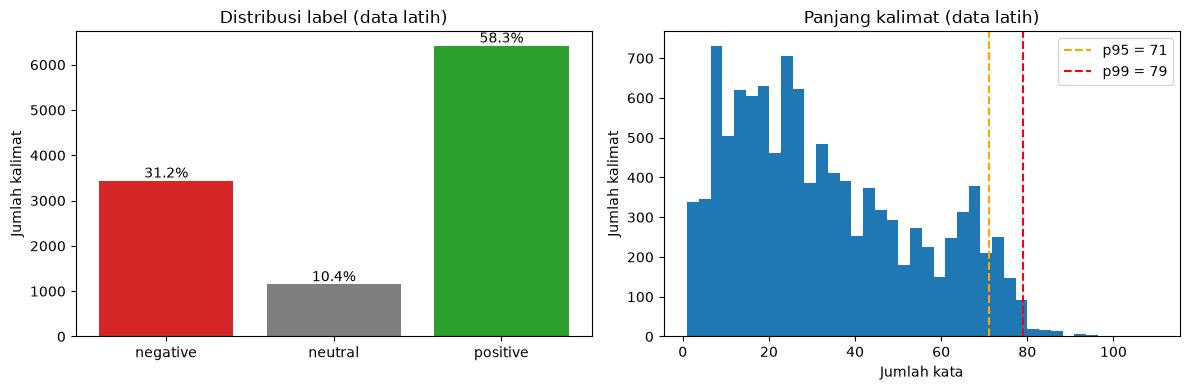

In [5]:
def tabel_distribusi_label(df):
    jumlah_per_label = df["label"].value_counts()
    tabel = pd.DataFrame({
        "jumlah": jumlah_per_label,
        "persen": (jumlah_per_label / len(df) * 100).round(1),
    })
    tabel = tabel.reindex(LABEL_LIST)
    return tabel

def hitung_jumlah_kata(df):
    kata_per_kalimat = df["text"].str.split()
    return kata_per_kalimat.str.len()

def ringkas_panjang_kalimat(jumlah_kata):
    return {
        "median": float(np.median(jumlah_kata)),
        "p95": float(np.percentile(jumlah_kata, 95)),
        "p99": float(np.percentile(jumlah_kata, 99)),
        "maks": int(jumlah_kata.max()),
    }

# Distribusi label 
print("Data Train:")
display(tabel_distribusi_label(data_latih_mentah))
print("\nData Validasi:")
display(tabel_distribusi_label(data_valid_mentah))

# Panjang kalimat 
jumlah_kata_latih = hitung_jumlah_kata(data_latih_mentah)
statistik_panjang = ringkas_panjang_kalimat(jumlah_kata_latih)
print("PANJANG KALIMAT — data latih (dalam kata)")
for nama, nilai in statistik_panjang.items():
    print(f"  {nama:<6}: {nilai:.0f}")

# Contoh kalimat per label
print("\nCONTOH KALIMAT PER LABEL")
for nama_label in LABEL_LIST:
    baris_label = data_latih_mentah[data_latih_mentah["label"] == nama_label]
    contoh_teks = baris_label["text"].iloc[0]
    print(f"  [{nama_label}] {contoh_teks[:150]}")

# visualisasi
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
distribusi_latih = tabel_distribusi_label(data_latih_mentah)
axes[0].bar(distribusi_latih.index, distribusi_latih["jumlah"], color=["#d62728", "#7f7f7f", "#2ca02c"])
axes[0].set_title("Distribusi label (data latih)")
axes[0].set_ylabel("Jumlah kalimat")
for posisi, (jumlah, persen) in enumerate(zip(distribusi_latih["jumlah"], distribusi_latih["persen"])):
    axes[0].text(posisi, jumlah, f"{persen}%", ha="center", va="bottom")

axes[1].hist(jumlah_kata_latih, bins=40, color="#1f77b4")
axes[1].axvline(statistik_panjang["p95"], color="orange", linestyle="--", label=f"p95 = {statistik_panjang['p95']:.0f}")
axes[1].axvline(statistik_panjang["p99"], color="red", linestyle="--", label=f"p99 = {statistik_panjang['p99']:.0f}")
axes[1].set_title("Panjang kalimat (data latih)")
axes[1].set_xlabel("Jumlah kata")
axes[1].set_ylabel("Jumlah kalimat")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_smsa.png", dpi=150, bbox_inches="tight")
plt.show()

## Cleaning Dataset

#### Pembersihan data

**Apa yang dilakukan?** Tiga langkah pembersihan otomatis, dengan jumlah baris dicetak di setiap langkah:
1. **Buang duplikat persis**, yaitu baris dengan teks dan label yang sama persis. Duplikat membuat model
   "melihat" kalimat yang sama berkali-kali, sehingga kalimat itu terlalu berpengaruh.
2. **Buang teks berlabel bertentangan**, yaitu teks yang sama tetapi labelnya berbeda. Contoh seperti ini
   membingungkan model, dan kita tidak tahu label mana yang benar, jadi semua barisnya dibuang.
3. **Buang teks validasi yang juga ada di data latih** (*kebocoran data*). Kalau kalimat yang sama
   ada di kedua set, model hanya "mengingat", bukan benar-benar memahami. Akibatnya skor validasi
   terlihat lebih bagus dari kemampuan sebenarnya.

Langkah 1 dan 2 diterapkan ke data latih dan validasi. Langkah 3 hanya ke validasi.

Setelah itu, label teks diubah menjadi angka (`negative=0`, `neutral=1`, `positive=2`), karena model
hanya bisa bekerja dengan angka. Di `MODE="uji"`, data latih dipotong menjadi 500 baris secara
**stratified**, artinya proporsi ketiga label tetap sama seperti data aslinya.

In [6]:
from sklearn.model_selection import train_test_split

# utk data duplicate
def hapus_duplikat_persis(df):
    df_bersih = df.drop_duplicates(subset=["text", "label"], keep="first")
    return df_bersih, len(df) - len(df_bersih)

# buang data yang teksnya muncul lebih dari satu label
def hapus_label_bertentangan(df):
    jumlah_label_per_teks = df.groupby("text")["label"].nunique()
    teks_bertentangan = jumlah_label_per_teks[jumlah_label_per_teks > 1].index
    df_bersih = df[~df["text"].isin(teks_bertentangan)]
    return df_bersih, len(teks_bertentangan)

# hapus data yg leakage
def hapus_kebocoran_validasi(df_valid, df_latih):
    teks_latih = set(df_latih["text"])
    df_bersih = df_valid[~df_valid["text"].isin(teks_latih)]
    return df_bersih, len(df_valid) - len(df_bersih)

# membuat pembagian data dengan proposi sama banyak
def ambil_subset_stratified(df, jumlah, seed):
    df_subset, _ = train_test_split(
        df, train_size=jumlah, stratify=df["label"], random_state=seed
    )
    return df_subset


# utk data train
latih_1, jumlah_duplikat_latih = hapus_duplikat_persis(data_latih_mentah)
latih_2, jumlah_konflik_latih = hapus_label_bertentangan(latih_1)

# untuk data validasi
valid_1, jumlah_duplikat_valid = hapus_duplikat_persis(data_valid_mentah)
valid_2, jumlah_konflik_valid = hapus_label_bertentangan(valid_1)

# utk data yang bocor di hapus
valid_3, jumlah_bocor = hapus_kebocoran_validasi(valid_2, latih_2)


ringkasan_pembersihan = pd.DataFrame(
    {
        "latih": [len(data_latih_mentah), jumlah_duplikat_latih, jumlah_konflik_latih, 0, len(latih_2)],
        "validasi": [len(data_valid_mentah), jumlah_duplikat_valid, jumlah_konflik_valid, jumlah_bocor, len(valid_3)],
    },
    index=["awal", "duplikat dibuang", "teks label bertentangan", "teks bocor dibuang", "akhir"],
)
print("RINGKASAN PEMBERSIHAN")
display(ringkasan_pembersihan)

# Cek dengan angka yang sudah diverifikasi sebelumnya (peringatan saja, bukan error,
# karena data sumber bisa saja diperbarui oleh pemiliknya).
if len(latih_2) == 10933:
    print("Data latih bersih = 10933, sesuai verifikasi")
else:
    print(f"Data latih bersih = {len(latih_2)}, berbeda dari verifikasi (10933). Cek sumber data.")

# --- Ubah label teks menjadi angka ---
DATA_LATIH = latih_2.reset_index(drop=True).copy()
DATA_VALID = valid_3.reset_index(drop=True).copy()
DATA_LATIH["label_id"] = DATA_LATIH["label"].map(LABEL2ID)
DATA_VALID["label_id"] = DATA_VALID["label"].map(LABEL2ID)

# --- Subset untuk MODE="uji" ---
if PENGATURAN["subset_latih"] is not None:
    DATA_LATIH = ambil_subset_stratified(DATA_LATIH, PENGATURAN["subset_latih"], seed=SEEDS[0])
    DATA_LATIH = DATA_LATIH.reset_index(drop=True)
    print(f"\nMODE='uji': data latih dipotong menjadi {len(DATA_LATIH)} baris (stratified)")

# --- Hasil akhir ---
print(f"\nDATA_LATIH : {len(DATA_LATIH)} baris")
print(f"DATA_VALID : {len(DATA_VALID)} baris")
print("\nDistribusi label akhir — DATA_LATIH")
display(tabel_distribusi_label(DATA_LATIH))
print("Distribusi label akhir — DATA_VALID")
display(tabel_distribusi_label(DATA_VALID))
print("Contoh baris siap pakai:")
display(DATA_LATIH.head(3))

RINGKASAN PEMBERSIHAN


,latih,validasi
awal,11000,1260
duplikat dibuang,67,0
teks label bertentangan,0,0
teks bocor dibuang,0,14
akhir,10933,1246


Data latih bersih = 10933, sesuai verifikasi

MODE='uji': data latih dipotong menjadi 500 baris (stratified)

DATA_LATIH : 500 baris
DATA_VALID : 1246 baris

Distribusi label akhir — DATA_LATIH


,jumlah,persen
label,,
negative,156,31.2
neutral,52,10.4
positive,292,58.4


Distribusi label akhir — DATA_VALID


,jumlah,persen
label,,
negative,389,31.2
neutral,129,10.4
positive,728,58.4


Contoh baris siap pakai:


,text,label,label_id
0,"dengar dari teman tempat ini bagus , bisa buat...",negative,0
1,ahmad dani pengecut banget sih . tidak berani ...,negative,0
2,"mohon bantu viralkan man teman , biar si bangs...",negative,0


#### Analisis
- Data latih: 11000 → **10933** (67 duplikat dibuang, 0 label bertentangan)
- Data validasi: 1260 → **sekitar 1246** (14 teks bocor dibuang; bisa berbeda sedikit kalau
  validasi juga punya duplikat)
- Distribusi label akhir. Di mode uji, data latih tercetak 500 baris dengan proporsi yang mirip.

## Tokenisasi dan Dataset

**Apa yang dilakukan?**
1. Memuat *tokenizer* untuk setiap backbone yang dipakai pada `MODE` saat ini.
2. Mengubah semua kalimat menjadi token, lalu membungkusnya dalam `DatasetSentimen` agar bisa dibaca Trainer.
3. Menampilkan contoh hasil tokenisasi dan statistik panjang token untuk mengecek apakah `max_length=128` cukup.
4. Mencoba `DataCollatorWithPadding` pada 4 contoh untuk melihat cara kerja padding.

**Konsep singkat:**
- **Tokenisasi:** model tidak membaca huruf, tetapi angka. Tokenizer memecah kalimat menjadi potongan kecil
  (*token*), misalnya `"pelayanannya"` bisa menjadi `pelayanan` + `##nya`, lalu setiap token diganti dengan
  nomor dari kamus (*vocabulary*) model. Setiap backbone punya tokenizer dan kamus sendiri, jadi kalimat yang
  sama bisa menghasilkan jumlah token yang berbeda.
- **Truncation:** kalimat yang lebih panjang dari `max_length` dipotong.
- **Padding:** di satu batch, semua kalimat harus sama panjang, jadi kalimat pendek ditambah token kosong
  (`[PAD]`). `attention_mask` memberi tahu model mana token asli (1) dan mana padding (0).
- **Dynamic padding:** `DataCollatorWithPadding` hanya menambah padding sampai kalimat terpanjang *di batch itu*,
  bukan selalu sampai 128. Hasilnya lebih hemat memori dan lebih cepat.

Hasil tokenisasi disimpan di `CACHE_DATASET`, sehingga setiap backbone cukup ditokenisasi sekali walaupun
dipakai di beberapa strategi dan seed.

In [7]:
# membuat fungsi tokenisasi utk membungkus hasil token dan label utk data train
class DatasetSentimen(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings   # dict: input_ids, attention_mask, (token_type_ids)
        self.labels = labels         # list angka label

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, indeks):
        item = {}
        for nama_kolom, semua_nilai in self.encodings.items():
            item[nama_kolom] = semua_nilai[indeks]
        # Trainer mencari label dengan nama kunci "labels".
        item["labels"] = int(self.labels[indeks])
        return item

# Mengubah list kalimat menjadi token, dipotong sampai MAX_LENGTH.
def tokenisasi_teks(tokenizer, daftar_teks):
    return tokenizer(daftar_teks, truncation=True, max_length=MAX_LENGTH)

CACHE_DATASET = {}

# tokenizer utk data train + validasi utk 1 backbone
def siapkan_dataset(checkpoint):
    if checkpoint in CACHE_DATASET:
        return CACHE_DATASET[checkpoint]

    tokenizer = AutoTokenizer.from_pretrained(checkpoint)
    encoding_latih = tokenisasi_teks(tokenizer, DATA_LATIH["text"].tolist())
    encoding_valid = tokenisasi_teks(tokenizer, DATA_VALID["text"].tolist())

    paket = {
        "tokenizer": tokenizer,
        "latih": DatasetSentimen(encoding_latih, DATA_LATIH["label_id"].tolist()),
        "valid": DatasetSentimen(encoding_valid, DATA_VALID["label_id"].tolist()),
    }
    CACHE_DATASET[checkpoint] = paket
    return paket
    
# menghitung panjang token
def statistik_panjang_token(tokenizer, daftar_teks):
    """Menghitung panjang token setiap kalimat TANPA dipotong, lalu meringkasnya."""
    hasil_tanpa_potong = tokenizer(daftar_teks, truncation=False)
    panjang_token = []
    for ids in hasil_tanpa_potong["input_ids"]:
        panjang_token.append(len(ids))
    panjang_token = np.array(panjang_token)
    return {
        "median": int(np.median(panjang_token)),
        "p99": int(np.percentile(panjang_token, 99)),
        "maks": int(panjang_token.max()),
        "persen_terpotong": round(float((panjang_token > MAX_LENGTH).mean() * 100), 2),
    }


# Tokenisasi untuk semua backbone pada MODE ini
baris_statistik = []
for backbone in PENGATURAN["backbones"]:
    checkpoint = BACKBONES[backbone]
    print(f"Menyiapkan tokenizer dan dataset: {checkpoint}")
    paket = siapkan_dataset(checkpoint)
    statistik = statistik_panjang_token(paket["tokenizer"], DATA_VALID["text"].tolist())
    statistik["backbone"] = backbone
    statistik["ukuran_vocab"] = paket["tokenizer"].vocab_size
    baris_statistik.append(statistik)

print("\nPANJANG TOKEN PER BACKBONE (dihitung pada data validasi, tanpa dipotong)")
tabel_token = pd.DataFrame(baris_statistik)
display(tabel_token[["backbone", "ukuran_vocab", "median", "p99", "maks", "persen_terpotong"]])

# Contoh hasil tokenisasi (backbone pertama)
backbone_contoh = PENGATURAN["backbones"][0]
tokenizer_contoh = CACHE_DATASET[BACKBONES[backbone_contoh]]["tokenizer"]
kalimat_contoh = DATA_LATIH["text"].iloc[0]
hasil_contoh = tokenizer_contoh(kalimat_contoh, truncation=True, max_length=MAX_LENGTH)

print(f"\nCONTOH TOKENISASI ({backbone_contoh})")
print(f"  Kalimat    : {kalimat_contoh[:120]}")
print(f"  Token      : {tokenizer_contoh.convert_ids_to_tokens(hasil_contoh['input_ids'])[:20]} ...")
print(f"  input_ids  : {hasil_contoh['input_ids'][:20]} ...")
print(f"  Jumlah token: {len(hasil_contoh['input_ids'])}")

# Cara kerja padding di DataCollatorWithPadding ---
collator_contoh = DataCollatorWithPadding(tokenizer=tokenizer_contoh)
dataset_contoh = CACHE_DATASET[BACKBONES[backbone_contoh]]["latih"]
empat_sampel = []
for indeks in range(4):
    empat_sampel.append(dataset_contoh[indeks])
batch_contoh = collator_contoh(empat_sampel)

print("\nCONTOH BATCH SETELAH PADDING (4 kalimat)")
for nama_kolom, tensor in batch_contoh.items():
    print(f"  {nama_kolom:<15}: {tuple(tensor.shape)}")
print("  attention_mask baris pertama (1 = token asli, 0 = padding):")
print(f"  {batch_contoh['attention_mask'][0].tolist()}")

Menyiapkan tokenizer dan dataset: bert-base-multilingual-cased
Menyiapkan tokenizer dan dataset: distilbert-base-multilingual-cased
Menyiapkan tokenizer dan dataset: indobenchmark/indobert-base-p1
Menyiapkan tokenizer dan dataset: xlm-roberta-base

PANJANG TOKEN PER BACKBONE (dihitung pada data validasi, tanpa dipotong)


,backbone,ukuran_vocab,median,p99,maks,persen_terpotong
0,mbert,119547,43,113,131,0.08
1,distilbert,119547,43,113,131,0.08
2,indobert,30521,32,87,104,0.00
3,xlmr,250002,39,105,122,0.00



CONTOH TOKENISASI (mbert)
  Kalimat    : dengar dari teman tempat ini bagus , bisa buat foto-foto prewedding , etc. usaha dech ke sana tapi mengecewakan , sih . 
  Token      : ['[CLS]', 'den', '##gar', 'dari', 'teman', 'tempat', 'ini', 'bag', '##us', ',', 'bisa', 'bu', '##at', 'foto', '-', 'foto', 'pre', '##wedd', '##ing', ','] ...
  input_ids  : [101, 10140, 14415, 10397, 71476, 16860, 10592, 56332, 10251, 117, 17103, 11499, 10526, 27218, 118, 27218, 12229, 72128, 10230, 117] ...
  Jumlah token: 68

CONTOH BATCH SETELAH PADDING (4 kalimat)
  input_ids      : (4, 79)
  token_type_ids : (4, 79)
  attention_mask : (4, 79)
  labels         : (4,)
  attention_mask baris pertama (1 = token asli, 0 = padding):
  [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## Model, Head Replacement, dan Strategi Freezing

**Apa yang dilakukan?**
1. `bangun_model()` memuat backbone pretrained lalu memasang **head baru** dengan 3 output
   (`num_labels=3`), lengkap dengan nama label (`id2label`, `label2id`).
2. `terapkan_strategi()` mengatur bagian mana yang dilatih dan mana yang dibekukan.
3. Sebagai contoh, satu model dimuat dan bagian head-nya ditampilkan.

**Konsep singkat:**
- **Head replacement:** checkpoint pretrained tidak punya head untuk sentimen. `from_pretrained` dengan
  `num_labels=3` membuat head baru yang bobotnya masih acak. Karena itu muncul pesan seperti
  *"Some weights ... were not initialized ... classifier.weight"*. **Pesan ini normal**, dan justru
  menjadi bukti bahwa head memang baru.
- **Freezing dan `requires_grad`:** setiap parameter punya tanda `requires_grad`. Kalau `True`, parameter
  diperbarui saat pelatihan. Kalau `False`, parameter "dibekukan" dan tidak berubah. Ibaratnya mengunci
  sebagian halaman buku supaya tidak bisa dicoret, dan hanya halaman lain yang boleh direvisi.

**Tiga strategi:**
| Strategi | Dibekukan | Dilatih |
|---|---|---|
| `full` | tidak ada | semua parameter |
| `partial` | embedding + separuh layer awal (12 layer → 6; DistilBERT 6 → 3) | separuh layer akhir, pooler (BERT), head |
| `probing` | seluruh backbone (`model.base_model`) | head saja |

Lokasi layer berbeda antar arsitektur:
- BERT, IndoBERT, XLM-R: `model.base_model.encoder.layer`
- DistilBERT: `model.base_model.transformer.layer`

Head juga berbeda: BERT/IndoBERT memakai `classifier`, DistilBERT memakai `pre_classifier` + `classifier`,
dan XLM-R memakai `classifier.dense` + `classifier.out_proj`. Semuanya berada **di luar** `base_model`,
sehingga di strategi probing head otomatis tetap dilatih.

In [8]:
# Memuat backbone pretrained dan memasang head klasifikasi
def bangun_model(checkpoint):
    model = AutoModelForSequenceClassification.from_pretrained(
        checkpoint,
        num_labels=len(LABEL_LIST),
        id2label=ID2LABEL,
        label2id=LABEL2ID,
    )
    return model

# ambil daftar layer Transformer
def ambil_layer_encoder(model):
    backbone = model.base_model
    if hasattr(backbone, "encoder"):        # BERT, IndoBERT, XLM-R
        return backbone.encoder.layer
    if hasattr(backbone, "transformer"):    # DistilBERT
        return backbone.transformer.layer
    raise ValueError(f"Arsitektur tidak dikenali: {type(backbone).__name__}")

# membuat representasi beku semua parameter
def bekukan(modul):
    for parameter in modul.parameters():
        parameter.requires_grad = False

# mengatur paramter utk fine-tuning
def terapkan_strategi(model, strategi):
    # Mulai dari kondisi "semua dilatih", lalu bekukan sesuai strategi.
    for parameter in model.parameters():
        parameter.requires_grad = True

    if strategi == "full":
        return model

    if strategi == "partial":
        bekukan(model.base_model.embeddings)
        daftar_layer = ambil_layer_encoder(model)
        jumlah_layer_beku = len(daftar_layer) // 2
        for indeks in range(jumlah_layer_beku):
            bekukan(daftar_layer[indeks])
        return model

    if strategi == "probing":
        # Seluruh backbone dibekukan (termasuk pooler BERT); head berada di luar base_model.
        bekukan(model.base_model)
        return model

    raise ValueError(f"Strategi tidak dikenal: {strategi}")


def hitung_parameter(model):
    total = 0
    dilatih = 0
    for parameter in model.parameters():
        total += parameter.numel()
        if parameter.requires_grad:
            dilatih += parameter.numel()
    return total, dilatih


def ambil_parameter_head(model):
    id_parameter_backbone = set()
    for parameter in model.base_model.parameters():
        id_parameter_backbone.add(id(parameter))

    parameter_head = []
    for nama, parameter in model.named_parameters():
        if id(parameter) not in id_parameter_backbone:
            parameter_head.append((nama, parameter))
    return parameter_head


# Contoh: lihat head baru pada backbone pertama 
checkpoint_contoh = BACKBONES[PENGATURAN["backbones"][0]]
set_seed(SEEDS[0])   # seed sebelum from_pretrained agar bobot awal head selalu sama
model_contoh = bangun_model(checkpoint_contoh)

print(f"\nHEAD BARU pada {checkpoint_contoh}:")
for nama, parameter in ambil_parameter_head(model_contoh):
    print(f"  {nama:<30} {tuple(parameter.shape)}")
print(f"\nid2label: {model_contoh.config.id2label}")

del model_contoh
gc.collect()

Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████| 199/199 [00:00<00:00, 15637.19it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you exp


HEAD BARU pada bert-base-multilingual-cased:
  classifier.weight              (3, 768)
  classifier.bias                (3,)

id2label: {0: 'negative', 1: 'neutral', 2: 'positive'}


54

## Cek Strategi dan Urutan Parameter

**Apa yang dilakukan?** Untuk setiap backbone × strategi pada `MODE` saat ini, model dimuat, strategi
diterapkan, lalu dihitung:
- jumlah parameter total dan yang dilatih (beserta persentasenya)
- status setiap bagian: embedding, tiap layer (`B` = beku, `L` = dilatih), pooler, dan head

Setelah itu notebook **memastikan** dengan `assert` bahwa:
- `full` melatih 100% parameter
- urutan parameter yang dilatih adalah **probing < partial < full**
- `probing` hanya melatih head, kurang dari 1% total parameter

**Kenapa perlu?** Kesalahan freezing tidak menimbulkan error. Model tetap berlatih, hanya saja dengan
strategi yang salah, sehingga seluruh perbandingan menjadi tidak valid. Pengecekan ini menangkap
kesalahan seperti itu sebelum 24 run dijalankan.

Model dimuat di CPU dan langsung dihapus, jadi tidak memakan VRAM. Pesan "newly initialized"
dimatikan mulai sel ini, karena sudah dijelaskan di atas dan akan muncul 24 kali saat pelatihan.

**Output yang seharusnya muncul (MODE="uji", IndoBERT; angka perkiraan):**
| strategi | total | dilatih | status layer |
|---|---|---|---|
| full | ~124,4 jt | ~124,4 jt (100%) | `LLLLLLLLLLLL` |
| partial | ~124,4 jt | ~43 jt (~35%) | `BBBBBBLLLLLL` |
| probing | ~124,4 jt | ~2.307 (<0,01%) | `BBBBBBBBBBBB` |

Perkiraan total parameter backbone lain: mBERT ~178 jt,
DistilBERT ~135 jt (6 layer), XLM-R ~278 jt.

In [9]:
# Matikan pesan 
transformers.logging.set_verbosity_error()

# 'L' kalau semua parameter dilatih, 'B' kalau semua beku, 'C' kalau campuran.
def status_modul(modul):
    daftar_status = []
    for parameter in modul.parameters():
        daftar_status.append(parameter.requires_grad)
    if all(daftar_status):
        return "L"
    if not any(daftar_status):
        return "B"
    return "C"

def ringkas_status_beku(model):
    status_layer = ""
    for layer in ambil_layer_encoder(model):
        status_layer += status_modul(layer)

    pooler = getattr(model.base_model, "pooler", None)
    status_pooler = status_modul(pooler) if pooler is not None else "-"

    status_head_semua = []
    for _, parameter in ambil_parameter_head(model):
        status_head_semua.append(parameter.requires_grad)
    status_head = "L" if all(status_head_semua) else "B"

    return {
        "embedding": status_modul(model.base_model.embeddings),
        "layer": status_layer,
        "pooler": status_pooler,
        "head": status_head,
    }

# cek setiap backbone dan strategi
def periksa_semua_konfigurasi():
    baris_tabel = []
    for backbone in PENGATURAN["backbones"]:
        checkpoint = BACKBONES[backbone]
        for strategi in MATRIKS_EKSPERIMEN[backbone]:
            set_seed(SEEDS[0])
            model = bangun_model(checkpoint)
            terapkan_strategi(model, strategi)
            total, dilatih = hitung_parameter(model)
            status = ringkas_status_beku(model)

            baris_tabel.append({
                "backbone": backbone,
                "strategy": strategi,
                "params_total": total,
                "params_trainable": dilatih,
                "persen_dilatih": round(dilatih / total * 100, 3),
                "embedding": status["embedding"],
                "layer": status["layer"],
                "pooler": status["pooler"],
                "head": status["head"],
            })
            print(f"  {backbone:<11} {strategi:<8} dilatih {dilatih:>12,} dari {total:>12,}")

            del model
            gc.collect()
    return pd.DataFrame(baris_tabel)

def cek_urutan_parameter(tabel):
    urutan_strategi = ["probing", "partial", "full"]
    for backbone in tabel["backbone"].unique():
        baris_backbone = tabel[tabel["backbone"] == backbone]
        dilatih_per_strategi = {}
        for _, baris in baris_backbone.iterrows():
            dilatih_per_strategi[baris["strategy"]] = baris["params_trainable"]
            if baris["strategy"] == "full":
                assert baris["params_trainable"] == baris["params_total"], f"{backbone} full tidak 100% dilatih"
            if baris["strategy"] == "probing":
                assert baris["persen_dilatih"] < 1, f"{backbone} probing melatih lebih dari head saja"
            assert baris["head"] == "L", f"Head {backbone} {baris['strategy']} ikut beku"

        # Bandingkan strategi yang dijalankan secara berurutan: probing < partial < full.
        strategi_ada = []
        for strategi in urutan_strategi:
            if strategi in dilatih_per_strategi:
                strategi_ada.append(strategi)
        for indeks in range(len(strategi_ada) - 1):
            lebih_sedikit = strategi_ada[indeks]
            lebih_banyak = strategi_ada[indeks + 1]
            assert dilatih_per_strategi[lebih_sedikit] < dilatih_per_strategi[lebih_banyak], (
                f"{backbone}: {lebih_sedikit} seharusnya melatih lebih sedikit parameter daripada {lebih_banyak}"
            )
        print(f"{backbone}: urutan {' < '.join(strategi_ada)} benar")


print("Memeriksa setiap konfigurasi (model dimuat di CPU, lalu dihapus)...")
TABEL_PARAMETER = periksa_semua_konfigurasi()

print("\nRINGKASAN PARAMETER DAN STATUS BEKU  (B = beku, L = dilatih)")
display(TABEL_PARAMETER)

print("\nCEK URUTAN PARAMETER")
cek_urutan_parameter(TABEL_PARAMETER)
print("Urutan parameter benar untuk semua backbone")

Memeriksa setiap konfigurasi (model dimuat di CPU, lalu dihapus)...


Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████| 199/199 [00:00<00:00, 9174.88it/s]


  mbert       full     dilatih  177,855,747 dari  177,855,747


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████| 199/199 [00:00<00:00, 13254.35it/s]


  mbert       partial  dilatih   43,120,131 dari  177,855,747


Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 9223.12it/s]


... (9 outputs left out)

Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████| 197/197 [00:00<00:00, 7257.60it/s]


  xlmr        full     dilatih  278,045,955 dari  278,045,955

RINGKASAN PARAMETER DAN STATUS BEKU  (B = beku, L = dilatih)


,backbone,strategy,params_total,params_trainable,persen_dilatih,embedding,layer,pooler,head
0,mbert,full,177855747,177855747,100.000,L,LLLLLLLLLLLL,L,L
1,mbert,partial,177855747,43120131,24.244,B,BBBBBBLLLLLL,L,L
2,distilbert,full,135326979,135326979,100.000,L,LLLLLL,-,L
3,distilbert,partial,135326979,21856515,16.151,B,BBBLLL,-,L
4,indobert,full,124443651,124443651,100.000,L,LLLLLLLLLLLL,L,L
5,indobert,partial,124443651,43120131,34.650,B,BBBBBBLLLLLL,L,L
6,indobert,probing,124443651,2307,0.002,B,BBBBBBBBBBBB,B,L
7,xlmr,full,278045955,278045955,100.000,L,LLLLLLLLLLLL,-,L



CEK URUTAN PARAMETER
mbert: urutan partial < full benar
distilbert: urutan partial < full benar
indobert: urutan probing < partial < full benar
xlmr: urutan full benar
Urutan parameter benar untuk semua backbone


## Metrik dan Pengukuran Waktu Inferensi

**Apa yang dilakukan?**
- `hitung_metrik()` menghitung akurasi, F1 makro, F1 per kelas (negatif, netral, positif),
  dan confusion matrix (disimpan sebagai teks JSON agar muat dalam satu sel CSV).
- `ukur_waktu_inferensi()` mengukur rata-rata waktu memprediksi **satu kalimat** (batch size 1).

**Aturan pengukuran inferensi** (sama untuk semua run agar adil):
- Sampel tetap: 200 kalimat validasi yang sama untuk semua model (diambil acak sekali dengan `random_state=0`).
- 10 prediksi pertama tidak dihitung (*warmup*). Prediksi awal di GPU biasanya lebih lambat karena
  GPU masih menyiapkan memori dan kernel, ibarat mesin mobil yang baru dinyalakan.
- **Tokenisasi tidak ikut diukur.** Semua kalimat ditokenisasi lebih dulu, jadi yang diukur murni waktu model.
- `torch.cuda.synchronize()` dipanggil sebelum dan sesudah pengukuran. GPU bekerja **asinkron**:
  Python bisa lanjut ke baris berikutnya sebelum GPU selesai menghitung. Tanpa sinkronisasi,
  waktu yang terukur bisa jauh lebih kecil dari kenyataannya.
- Presisi inferensi sama dengan pelatihan: fp16 (autocast) bila memakai GPU.

In [10]:
ID_LABEL_URUT = list(range(len(LABEL_LIST)))   # [0, 1, 2] = negative, neutral, positive

def hitung_metrik(label_benar, label_prediksi):
    f1_per_kelas = f1_score(
        label_benar, label_prediksi, labels=ID_LABEL_URUT, average=None, zero_division=0
    )
    matriks = confusion_matrix(label_benar, label_prediksi, labels=ID_LABEL_URUT)

    metrik = {
        "accuracy": float(accuracy_score(label_benar, label_prediksi)),
        "f1_macro": float(f1_score(
            label_benar, label_prediksi, labels=ID_LABEL_URUT, average="macro", zero_division=0
        )),
    }
    for indeks, nama_label in enumerate(LABEL_LIST):
        metrik[f"f1_{nama_label}"] = float(f1_per_kelas[indeks])
    metrik["confusion_matrix"] = json.dumps(matriks.tolist())
    return metrik

def sinkronkan_gpu():
    if DEVICE == "cuda":
        torch.cuda.synchronize()

# Mengukur rata-rata waktu prediksi per kalimat (ms) dengan batch size 1
def ukur_waktu_inferensi(model, tokenizer, daftar_teks, jumlah_warmup):
    perangkat = next(model.parameters()).device
    model.eval()

    # 1) Tokenisasi semua kalimat lebih dulu, supaya waktunya tidak ikut terukur.
    input_siap = []
    for teks in daftar_teks:
        hasil_token = tokenizer(teks, truncation=True, max_length=MAX_LENGTH, return_tensors="pt")
        satu_input = {}
        for nama_kolom, tensor in hasil_token.items():
            satu_input[nama_kolom] = tensor.to(perangkat)
        input_siap.append(satu_input)

    # 2) Warmup, lalu ukur. inference_mode mematikan perhitungan gradien (lebih cepat dan hemat).
    with torch.inference_mode():
        with torch.autocast(device_type=perangkat.type, dtype=torch.float16, enabled=USE_FP16):
            for indeks in range(jumlah_warmup):
                model(**input_siap[indeks])
            sinkronkan_gpu()

            waktu_mulai = time.perf_counter()
            for satu_input in input_siap:
                model(**satu_input)
            sinkronkan_gpu()
            waktu_selesai = time.perf_counter()

    return (waktu_selesai - waktu_mulai) / len(input_siap) * 1000

# Sampel inferensi tetap: kalimat yang sama untuk semua run.
TEKS_INFERENSI = DATA_VALID["text"].sample(n=INFER_JUMLAH_KALIMAT, random_state=0).tolist()
print(f"Sampel inferensi: {len(TEKS_INFERENSI)} kalimat")
print(f"Contoh: {TEKS_INFERENSI[0][:100]}")

Sampel inferensi: 200 kalimat
Contoh: ternyata nescafe asli indonesia banget . suka kopi . cinta indonesia . aku cinta produk indonesia .


## Fungsi run_one: Satu Run Lengkap

**Apa yang dilakukan?** Untuk satu kombinasi backbone × strategi × seed:
1. Mengambil dataset hasil tokenisasi (dari cache).
2. `set_seed(seed)` **sebelum** `from_pretrained`, supaya bobot acak awal head selalu sama untuk seed yang sama.
3. Membangun model, menerapkan strategi freezing, dan menghitung parameter.
4. Menghitung `warmup_steps` = 10% dari total step, sebagai bilangan bulat.
5. Melatih dengan `Trainer`, sambil mengukur waktu latih dan memori GPU puncak.
6. Memprediksi seluruh data validasi **satu kali** di akhir (tanpa early stopping), lalu menghitung metrik.
7. Mengukur waktu inferensi, lalu mengembalikan satu baris hasil.
8. Apa pun yang terjadi (berhasil atau error), model dihapus dan memori GPU dibersihkan. Ini penting di VRAM 6 GB,
   supaya run berikutnya tidak kehabisan memori.

**Konsep singkat:**
- **Trainer:** "pelatih otomatis" dari HuggingFace. Trainer mengurus loop pelatihan: membagi batch,
  menghitung loss, backpropagation, dan memperbarui bobot dengan **AdamW** (optimizer standar).
  Hanya parameter dengan `requires_grad=True` yang diperbarui.
- **Warmup + linear scheduler:** learning rate naik perlahan dari 0 selama 10% step awal, lalu turun
  linear sampai 0 di akhir. Kenaikan perlahan mencegah head yang masih acak "merusak" bobot pretrained
  di awal pelatihan.
- **Loss:** ukuran seberapa salah prediksi model. Selama pelatihan, nilai loss yang tercetak seharusnya cenderung turun.

**Kompatibilitas versi:** `buat_training_args()` hanya meneruskan argumen yang dikenali versi `transformers`
yang terpasang. Kalau ada argumen yang tidak dikenali, akan muncul `[PERINGATAN] Argumen ... dilewati`.
Laporkan kalau pesan ini muncul.

In [11]:
import dataclasses
import math
from transformers import TrainerCallback

def bersihkan_memori():
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

def buat_training_args(**argumen):
    nama_argumen_valid = set()
    for field in dataclasses.fields(TrainingArguments):
        nama_argumen_valid.add(field.name)

    argumen_dipakai = {}
    for nama, nilai in argumen.items():
        if nama in nama_argumen_valid:
            argumen_dipakai[nama] = nilai
        else:
            print(f"[PERINGATAN] Argumen '{nama}' tidak dikenal transformers {transformers.__version__}, dilewati")
    return TrainingArguments(**argumen_dipakai)

def hitung_total_step(jumlah_data, batch_size, epoch):
    step_per_epoch = math.ceil(jumlah_data / batch_size)
    return step_per_epoch * epoch

from transformers import TrainerCallback


class CetakProgres(TrainerCallback):
    def __init__(self, total_step):
        self.total_step = total_step
        self.interval = max(1, total_step // 10)
        self.waktu_mulai = None

    def on_train_begin(self, args, state, control, **kwargs):
        self.waktu_mulai = time.perf_counter()
        print(f"  Mulai melatih: {self.total_step} step")

    def on_step_end(self, args, state, control, **kwargs):
        step = state.global_step
        if step % self.interval == 0 or step == self.total_step:
            persen = step / self.total_step * 100
            detik = time.perf_counter() - self.waktu_mulai
            loss_terakhir = "-"
            if len(state.log_history) > 0 and "loss" in state.log_history[-1]:
                loss_terakhir = f"{state.log_history[-1]['loss']:.4f}"
            print(f"    step {step:>5}/{self.total_step} ({persen:5.1f}%) | {detik:6.1f} s | loss terakhir {loss_terakhir}")

# Menjalankan satu run: latih, evaluasi, ukur efisiensi
def run_one(run):
    paket = siapkan_dataset(run["checkpoint"])
    model = None
    trainer = None
    try:
        # 1) Model dan strategi
        set_seed(run["seed"])   # WAJIB sebelum from_pretrained: bobot awal head jadi deterministik
        model = bangun_model(run["checkpoint"])
        terapkan_strategi(model, run["strategy"])
        params_total, params_trainable = hitung_parameter(model)

        # 2) Pengaturan pelatihan
        total_step = hitung_total_step(len(paket["latih"]), run["batch_size"], run["epoch"])
        warmup_steps = int(total_step * WARMUP_RATIO)
        print(f"  Data latih {len(paket['latih'])} | total step {total_step} | warmup {warmup_steps} step")
        print(f"  Parameter dilatih: {params_trainable:,} dari {params_total:,} "
              f"({params_trainable / params_total * 100:.2f}%)")

        argumen_latih = buat_training_args(
            output_dir=str(OUTPUT_DIR / "tmp_trainer"),
            per_device_train_batch_size=run["batch_size"],
            per_device_eval_batch_size=64,      # hanya untuk prediksi; tidak memengaruhi hasil
            num_train_epochs=run["epoch"],
            learning_rate=run["lr"],
            weight_decay=WEIGHT_DECAY,
            lr_scheduler_type="linear",
            warmup_steps=warmup_steps,
            fp16=USE_FP16,
            seed=run["seed"],
            data_seed=run["seed"],
            save_strategy="no",                 # tidak menyimpan checkpoint bobot (resume per run via CSV)
            logging_strategy="steps",
            # logging_steps=100,
            logging_steps=max(1, total_step // 10),
            report_to="none",
        )
        trainer = Trainer(
            model=model,
            args=argumen_latih,
            train_dataset=paket["latih"],
            data_collator=DataCollatorWithPadding(tokenizer=paket["tokenizer"]),
            callbacks=[CetakProgres(total_step)]
        )

        # 3) Latih, ukur waktu dan memori puncak
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()   # mulai hitung memori puncak dari nol
        waktu_mulai = time.perf_counter()
        trainer.train()
        sinkronkan_gpu()
        train_time_s = time.perf_counter() - waktu_mulai

        if DEVICE == "cuda":
            peak_mem_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
        else:
            peak_mem_mb = float("nan")

        # 4) Evaluasi sekali di akhir pada validasi (tanpa early stopping) ---
        hasil_prediksi = trainer.predict(paket["valid"])
        logits = hasil_prediksi.predictions
        if isinstance(logits, tuple):           # beberapa model mengembalikan tuple
            logits = logits[0]
        label_prediksi = np.argmax(logits, axis=-1)
        metrik = hitung_metrik(hasil_prediksi.label_ids, label_prediksi)

        # 5) Waktu inferensi per kalimat ---
        infer_ms = ukur_waktu_inferensi(
            trainer.model, paket["tokenizer"], TEKS_INFERENSI, INFER_JUMLAH_WARMUP
        )

        # 6) Satu baris hasil ---
        baris_hasil = {
            "run_id": run["run_id"],
            "kode": KODE,
            "mode": run["mode"],
            "backbone": run["backbone"],
            "checkpoint": run["checkpoint"],
            "strategy": run["strategy"],
            "seed": run["seed"],
            "lr": run["lr"],
            "batch_size": run["batch_size"],
            "epoch": run["epoch"],
            "max_length": run["max_length"],
            "n_latih": len(paket["latih"]),
            "n_valid": len(paket["valid"]),
            "accuracy": metrik["accuracy"],
            "f1_macro": metrik["f1_macro"],
            "f1_negative": metrik["f1_negative"],
            "f1_neutral": metrik["f1_neutral"],
            "f1_positive": metrik["f1_positive"],
            "train_time_s": round(train_time_s, 2),
            "infer_ms_per_sentence": round(infer_ms, 3),
            "params_total": params_total,
            "params_trainable": params_trainable,
            "peak_mem_mb": round(peak_mem_mb, 1),
            "confusion_matrix": metrik["confusion_matrix"],
            "device": DEVICE,
            "gpu_name": GPU_NAME,
            "timestamp": datetime.now().isoformat(timespec="seconds"),
        }
        return baris_hasil

    finally:
        # Selalu dijalankan, baik run berhasil maupun error.
        del model
        del trainer
        bersihkan_memori()

## Loop Semua Run (dengan Resume)

**Apa yang dilakukan?**
1. Kalau `CSV_LANJUTAN` diisi dan CSV hasil belum ada, CSV lama disalin dulu. Kodenya dicek harus sama
   dengan `KODE` sekarang, supaya hasil dari konfigurasi berbeda tidak tercampur.
2. Membaca `run_id` yang sudah ada di `hasil_smsa_<kode>.csv`.
3. Menjalankan setiap run di `DAFTAR_RUN`:
   - Kalau sudah ada di CSV, run **dilewati**.
   - Kalau berhasil, hasilnya **langsung ditambahkan ke CSV** dan ringkasannya dicetak.
   - Kalau gagal (misalnya out of memory), pesannya dicetak, run **tidak** ditulis ke CSV, dan loop
     lanjut ke run berikutnya. Run yang gagal otomatis dicoba lagi saat sel ini dijalankan ulang.
4. Di akhir dicetak ringkasan: berapa run berhasil, dilewati, dan gagal.

**Kenapa resume per run?** Satu run hanya beberapa menit. Kalau sesi terputus, yang hilang paling
banyak satu run itu. Checkpoint bobot sengaja tidak disimpan: ukurannya ratusan MB per model,
dan waktu latih harus diukur utuh dalam satu kali jalan.

**Cara menghentikan:** *Kernel → Interrupt*. Run yang sedang berjalan dibatalkan, sedangkan run
yang sudah selesai tetap tersimpan di CSV.

**Output yang seharusnya muncul (MODE="uji", IndoBERT):** 3 blok run (`[1/3]`, `[2/3]`, `[3/3]`),
masing-masing dengan progress bar pelatihan lalu baris ringkasan metrik. Di akhir:
`Berhasil: 3 | Dilewati: 0 | Gagal: 0`, lalu tabel hasil.

Angka F1 di mode uji **wajar rendah** (500 data, 1 epoch). Probing bahkan bisa hanya menebak
"positive" (F1 makro sekitar 0,25). Mode uji hanya untuk mengecek kode, bukan untuk menilai hasil.

In [12]:
import shutil
import traceback

def baca_csv_hasil(path_csv):
    return pd.read_csv(path_csv, dtype={"kode": str})

# Menyalin CSV_LANJUTAN ke HASIL_CSV kalau perlu (khusus pemulihan sesi Kaggle)
def pulihkan_csv_lama():
    if CSV_LANJUTAN is None:
        return
    if HASIL_CSV.exists():
        print("[INFO] CSV hasil sudah ada, CSV_LANJUTAN diabaikan")
        return
    path_lama = Path(CSV_LANJUTAN)
    assert path_lama.exists(), f"CSV_LANJUTAN tidak ditemukan: {path_lama}"
    hasil_lama = baca_csv_hasil(path_lama)
    kode_di_csv_lama = set(hasil_lama["kode"])
    assert kode_di_csv_lama == {KODE}, (
        f"CSV lama memakai kode {kode_di_csv_lama}, sedangkan konfigurasi sekarang {KODE}. "
        "Hasil dari konfigurasi berbeda tidak boleh dicampur."
    )
    shutil.copy(path_lama, HASIL_CSV)
    print(f"[INFO] {len(hasil_lama)} run dipulihkan dari {path_lama}")

# Mengembalikan set run_id yang sudah tercatat di CSV
def baca_run_selesai(path_csv):
    if not path_csv.exists():
        return set()
    hasil_lama = baca_csv_hasil(path_csv)
    return set(hasil_lama["run_id"])
    
# Menambahkan satu baris ke CSV
# catatan : Header hanya ditulis kalau file belum ada
def tulis_baris_csv(path_csv, baris_hasil):
    tabel_satu_baris = pd.DataFrame([baris_hasil])
    tulis_header = not path_csv.exists()
    tabel_satu_baris.to_csv(path_csv, mode="a", header=tulis_header, index=False)

# cek GPU habus memory ga??
def adalah_error_oom(error):
    if isinstance(error, torch.cuda.OutOfMemoryError):
        return True
    return "out of memory" in str(error).lower()

def cetak_ringkasan_run(baris_hasil):
    print(
        f"  HASIL -> F1 makro {baris_hasil['f1_macro']:.4f} | akurasi {baris_hasil['accuracy']:.4f} | "
        f"F1 netral {baris_hasil['f1_neutral']:.4f} | latih {baris_hasil['train_time_s']:.1f} s | "
        f"inferensi {baris_hasil['infer_ms_per_sentence']:.2f} ms/kalimat | "
        f"memori puncak {baris_hasil['peak_mem_mb']:.0f} MB"
    )

# Persiapan
pulihkan_csv_lama()
run_selesai = baca_run_selesai(HASIL_CSV)
jumlah_run = len(DAFTAR_RUN)
jumlah_dilewati = 0
run_berhasil = []
run_gagal = []

print(f"MODE={MODE} | kode={KODE} | {jumlah_run} run | {len(run_selesai)} sudah ada di CSV")
print(f"CSV hasil: {HASIL_CSV}\n")
waktu_awal_loop = time.perf_counter()

# Loop
for nomor, run in enumerate(DAFTAR_RUN, start=1):
    label_progres = f"[{nomor}/{jumlah_run}] {run['run_id']}"

    if run["run_id"] in run_selesai:
        print(f"{label_progres} sudah ada di CSV, dilewati")
        jumlah_dilewati += 1
        continue

    print("=" * 70)
    print(f"{label_progres} | lr={run['lr']} | batch={run['batch_size']} | epoch={run['epoch']}")
    print("=" * 70)

    try:
        baris_hasil = run_one(run)
    except Exception as error:
        run_gagal.append(run["run_id"])
        if adalah_error_oom(error):
            print(f"  [GAGAL] {run['run_id']}: GPU kehabisan memori (out of memory).")
            if MODE == "uji":
                print("  Saran: kecilkan UJI_BATCH_SIZE di sel Konfigurasi (misalnya 4), lalu jalankan ulang sel ini.")
            else:
                print("  Batch mode penuh TIDAK boleh diubah (variabel terkendali). Jalankan di GPU Kaggle T4.")
        else:
            print(f"  [GAGAL] {run['run_id']}: {type(error).__name__}: {error}")
            traceback.print_exc()
        bersihkan_memori()
        continue

    tulis_baris_csv(HASIL_CSV, baris_hasil)
    run_berhasil.append(run["run_id"])
    cetak_ringkasan_run(baris_hasil)

# Ringkasan akhir
durasi_menit = (time.perf_counter() - waktu_awal_loop) / 60
print("\n" + "=" * 70)
print(f"SELESAI dalam {durasi_menit:.1f} menit")
print(f"Berhasil: {len(run_berhasil)} | Dilewati: {jumlah_dilewati} | Gagal: {len(run_gagal)}")
if len(run_gagal) > 0:
    print(f"[PERINGATAN] Run gagal: {run_gagal}")
    print("Jalankan ulang sel ini untuk mencoba lagi. Run yang sudah berhasil tidak akan diulang.")

if HASIL_CSV.exists():
    HASIL = baca_csv_hasil(HASIL_CSV)
    print(f"\nIsi {HASIL_CSV.name}: {len(HASIL)} baris")
    kolom_tampil = ["run_id", "f1_macro", "accuracy", "f1_neutral", "train_time_s",
                    "infer_ms_per_sentence", "params_trainable", "peak_mem_mb"]
    display(HASIL[kolom_tampil])

MODE=uji | kode=317c2d7c | 8 run | 0 sudah ada di CSV
CSV hasil: /home/sembiring/machine_learning/00_pr0j3ct/indo-sentiment-finetuning-benchmark/outputs/hasil_smsa_317c2d7c.csv

[1/8] mbert_full_s42 | lr=2e-05 | batch=8 | epoch=1


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████| 199/199 [00:00<00:00, 11031.08it/s]


  Data latih 500 | total step 63 | warmup 6 step
  Parameter dilatih: 177,855,747 dari 177,855,747 (100.00%)
  Mulai melatih: 63 step
    step     6/63 (  9.5%) |    0.8 s | loss terakhir -
{'loss': '1.055', 'grad_norm': '5.102', 'learning_rate': '1.667e-05', 'epoch': '0.09524'}
    step    12/63 ( 19.0%) |    1.3 s | loss terakhir 1.0546
{'loss': '0.9224', 'grad_norm': '5.548', 'learning_rate': '1.825e-05', 'epoch': '0.1905'}
    step    18/63 ( 28.6%) |    1.7 s | loss terakhir 0.9224
{'loss': '0.9232', 'grad_norm': '6.207', 'learning_rate': '1.614e-05', 'epoch': '0.2857'}
    step    24/63 ( 38.1%) |    2.3 s | loss terakhir 0.9232
{'loss': '0.8182', 'grad_norm': '5.936', 'learning_rate': '1.404e-05', 'epoch': '0.381'}
    step    30/63 ( 47.6%) |    2.8 s | loss terakhir 0.8182
{'loss': '0.665', 'grad_norm': '10.15', 'learning_rate': '1.193e-05', 'epoch': '0.4762'}
    step    36/63 ( 57.1%) |    3.4 s | loss terakhir 0.6650
{'loss': '0.6886', 'grad_norm': '5.69', 'learning_rate': 

Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████| 199/199 [00:00<00:00, 11975.82it/s]


  Data latih 500 | total step 63 | warmup 6 step
  Parameter dilatih: 43,120,131 dari 177,855,747 (24.24%)
  Mulai melatih: 63 step
    step     6/63 (  9.5%) |    0.2 s | loss terakhir -
{'loss': '1.055', 'grad_norm': '4.829', 'learning_rate': '1.667e-05', 'epoch': '0.09524'}
    step    12/63 ( 19.0%) |    0.4 s | loss terakhir 1.0548
{'loss': '0.9302', 'grad_norm': '4.585', 'learning_rate': '1.825e-05', 'epoch': '0.1905'}
    step    18/63 ( 28.6%) |    0.7 s | loss terakhir 0.9302
{'loss': '0.91', 'grad_norm': '5.259', 'learning_rate': '1.614e-05', 'epoch': '0.2857'}
    step    24/63 ( 38.1%) |    0.9 s | loss terakhir 0.9100
{'loss': '0.8111', 'grad_norm': '4.227', 'learning_rate': '1.404e-05', 'epoch': '0.381'}
    step    30/63 ( 47.6%) |    1.2 s | loss terakhir 0.8111
{'loss': '0.7201', 'grad_norm': '6.827', 'learning_rate': '1.193e-05', 'epoch': '0.4762'}
    step    36/63 ( 57.1%) |    1.4 s | loss terakhir 0.7201
{'loss': '0.7854', 'grad_norm': '4.056', 'learning_rate': '9

Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 10786.99it/s]


... (8 outputs left out)

  Data latih 500 | total step 63 | warmup 6 step
  Parameter dilatih: 2,307 dari 124,443,651 (0.00%)
  Mulai melatih: 63 step
    step     6/63 (  9.5%) |    0.1 s | loss terakhir -
{'loss': '1.087', 'grad_norm': '7.053', 'learning_rate': '0.0008333', 'epoch': '0.09524'}
    step    12/63 ( 19.0%) |    0.2 s | loss terakhir 1.0869
{'loss': '0.9966', 'grad_norm': '7.458', 'learning_rate': '0.0009123', 'epoch': '0.1905'}
    step    18/63 ( 28.6%) |    0.2 s | loss terakhir 0.9966
{'loss': '0.9595', 'grad_norm': '6.079', 'learning_rate': '0.000807', 'epoch': '0.2857'}
    step    24/63 ( 38.1%) |    0.3 s | loss terakhir 0.9595
{'loss': '0.7604', 'grad_norm': '4.921', 'learning_rate': '0.0007018', 'epoch': '0.381'}
    step    30/63 ( 47.6%) |    0.4 s | loss terakhir 0.7604
{'loss': '0.589', 'grad_norm': '6.391', 'learning_rate': '0.0005965', 'epoch': '0.4762'}
    step    36/63 ( 57.1%) |    0.5 s | loss terakhir 0.5890
{'loss': '0.7102', 'grad_norm': '4.193', 'learning_rate': '0.00049

Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████| 197/197 [00:00<00:00, 5156.44it/s]


  Data latih 500 | total step 63 | warmup 6 step
  Parameter dilatih: 278,045,955 dari 278,045,955 (100.00%)
  Mulai melatih: 63 step
    step     6/63 (  9.5%) |    0.7 s | loss terakhir -
{'loss': '1.063', 'grad_norm': '5.547', 'learning_rate': '1.667e-05', 'epoch': '0.09524'}
    step    12/63 ( 19.0%) |    1.3 s | loss terakhir 1.0626
{'loss': '1.035', 'grad_norm': '5.105', 'learning_rate': '1.825e-05', 'epoch': '0.1905'}
    step    18/63 ( 28.6%) |    2.0 s | loss terakhir 1.0350
{'loss': '1.011', 'grad_norm': '7.611', 'learning_rate': '1.614e-05', 'epoch': '0.2857'}
    step    24/63 ( 38.1%) |    2.7 s | loss terakhir 1.0108
{'loss': '0.9704', 'grad_norm': '2.237', 'learning_rate': '1.404e-05', 'epoch': '0.381'}
    step    30/63 ( 47.6%) |    3.4 s | loss terakhir 0.9704
{'loss': '0.9135', 'grad_norm': '7.38', 'learning_rate': '1.193e-05', 'epoch': '0.4762'}
    step    36/63 ( 57.1%) |    4.1 s | loss terakhir 0.9135
{'loss': '0.9314', 'grad_norm': '3.749', 'learning_rate': '

,run_id,f1_macro,accuracy,f1_neutral,train_time_s,infer_ms_per_sentence,params_trainable,peak_mem_mb
0,mbert_full_s42,0.513806,0.754414,0.000000,6.07,4.090,177855747,2754.5
1,mbert_partial_s42,0.496193,0.735955,0.000000,2.66,3.788,43120131,1346.4
2,distilbert_full_s42,0.276634,0.595506,0.000000,4.13,2.022,135326979,2096.0
3,distilbert_partial_s42,0.245863,0.584270,0.000000,1.38,2.059,21856515,867.5
4,indobert_full_s42,0.792561,0.847512,0.681818,4.41,3.757,124443651,1969.0
5,indobert_partial_s42,0.761626,0.836276,0.605128,2.33,3.907,43120131,1097.2
6,indobert_probing_s42,0.523253,0.759230,0.015385,0.99,3.654,2307,510.7
7,xlmr_full_s42,0.245863,0.584270,0.000000,7.42,3.805,278045955,4287.2


# Rekap agregat, visualisasi, uji selisih bermakna

**Apa yang dilakukan?** Mengelompokkan hasil per kombinasi **backbone × strategi**, lalu menghitung
rata-rata (*mean*) dan simpangan baku (*std*) dari semua metrik di seluruh seed. Hasilnya juga ditulis
dalam bentuk teks `"mean ± std"`, lalu disimpan ke `rekap_agregat_smsa_<kode>.csv`.

**Konsep singkat: simpangan baku antar-seed.** Kalau konfigurasi yang sama dijalankan dengan 3 seed,
hasilnya sedikit berbeda karena inisialisasi head dan urutan data berbeda. Simpangan baku mengukur
seberapa besar "goyangan" itu. Std kecil berarti hasilnya stabil. Std besar berarti hasilnya bergantung
pada keberuntungan seed. Yang dipakai adalah std sampel (ddof=1), standar untuk jumlah ulangan kecil.

## REKAP AGREGAT

In [15]:
URUTAN_BACKBONE = list(MATRIKS_EKSPERIMEN.keys())      # mbert, distilbert, indobert, xlmr
URUTAN_STRATEGI = ["full", "partial", "probing"]
NAMA_BACKBONE = {"mbert": "mBERT", "distilbert": "DistilBERT", "indobert": "IndoBERT", "xlmr": "XLM-R"}

# Metrik yang direkap, beserta jumlah desimal untuk teks "mean ± std".
METRIK_REKAP = {
    "f1_macro": 4,
    "accuracy": 4,
    "f1_negative": 4,
    "f1_neutral": 4,
    "f1_positive": 4,
    "train_time_s": 1,
    "infer_ms_per_sentence": 3,
    "peak_mem_mb": 0,
    "params_total": 0,
    "params_trainable": 0,
}

# Mengubah mean dan std menjadi teks
def format_mean_std(nilai_mean, nilai_std, desimal):
    if pd.isna(nilai_std):
        return f"{nilai_mean:.{desimal}f} ± -"
    return f"{nilai_mean:.{desimal}f} ± {nilai_std:.{desimal}f}"

def buat_rekap_agregat(hasil):
    baris_rekap = []
    for (backbone, strategi), kelompok in hasil.groupby(["backbone", "strategy"]):
        daftar_seed = sorted(kelompok["seed"].tolist())
        baris = {
            "kode": KODE,
            "mode": MODE,
            "backbone": backbone,
            "strategy": strategi,
            "n_seed": len(kelompok),
            "seeds": ", ".join(str(seed) for seed in daftar_seed),
        }
        for metrik, desimal in METRIK_REKAP.items():
            nilai_mean = kelompok[metrik].mean()
            nilai_std = kelompok[metrik].std()      # std sampel (ddof=1); NaN kalau hanya 1 seed
            baris[f"{metrik}_mean"] = nilai_mean
            baris[f"{metrik}_std"] = nilai_std
            baris[f"{metrik}_teks"] = format_mean_std(nilai_mean, nilai_std, desimal)
        baris_rekap.append(baris)

    rekap = pd.DataFrame(baris_rekap)
    # Urutkan sesuai urutan matriks, bukan urutan abjad.
    rekap["backbone"] = pd.Categorical(rekap["backbone"], categories=URUTAN_BACKBONE, ordered=True)
    rekap["strategy"] = pd.Categorical(rekap["strategy"], categories=URUTAN_STRATEGI, ordered=True)
    rekap = rekap.sort_values(["backbone", "strategy"]).reset_index(drop=True)
    rekap["backbone"] = rekap["backbone"].astype(str)
    rekap["strategy"] = rekap["strategy"].astype(str)
    return rekap

# Baca ulang CSV supaya rekap selalu memakai data terbaru dari file
assert HASIL_CSV.exists(), f"CSV hasil belum ada: {HASIL_CSV}. Jalankan loop pelatihan dulu."
HASIL = baca_csv_hasil(HASIL_CSV)
REKAP = buat_rekap_agregat(HASIL)
REKAP.to_csv(REKAP_CSV, index=False)

if MODE == "penuh":
    assert len(REKAP) == 8, f"Mode penuh seharusnya 8 kombinasi, ternyata {len(REKAP)}"
    assert (REKAP["n_seed"] == 3).all(), "Ada kombinasi yang belum lengkap 3 seed. Jalankan ulang loop pelatihan."

print(f"Rekap disimpan: {REKAP_CSV}")
print(f"{len(HASIL)} run -> {len(REKAP)} kombinasi backbone x strategi\n")

kolom_tampil = [
    "backbone", "strategy", "n_seed",
    "f1_macro_teks", "accuracy_teks", "f1_neutral_teks",
    "train_time_s_teks", "infer_ms_per_sentence_teks", "peak_mem_mb_teks",
]
display(REKAP[kolom_tampil])

Rekap disimpan: /home/sembiring/machine_learning/00_pr0j3ct/indo-sentiment-finetuning-benchmark/outputs/rekap_agregat_smsa_317c2d7c.csv
8 run -> 8 kombinasi backbone x strategi



,backbone,strategy,n_seed,f1_macro_teks,accuracy_teks,f1_neutral_teks,train_time_s_teks,infer_ms_per_sentence_teks,peak_mem_mb_teks
0,mbert,full,1,0.5138 ± -,0.7544 ± -,0.0000 ± -,6.1 ± -,4.090 ± -,2754 ± -
1,mbert,partial,1,0.4962 ± -,0.7360 ± -,0.0000 ± -,2.7 ± -,3.788 ± -,1346 ± -
2,distilbert,full,1,0.2766 ± -,0.5955 ± -,0.0000 ± -,4.1 ± -,2.022 ± -,2096 ± -
3,distilbert,partial,1,0.2459 ± -,0.5843 ± -,0.0000 ± -,1.4 ± -,2.059 ± -,868 ± -
4,indobert,full,1,0.7926 ± -,0.8475 ± -,0.6818 ± -,4.4 ± -,3.757 ± -,1969 ± -
5,indobert,partial,1,0.7616 ± -,0.8363 ± -,0.6051 ± -,2.3 ± -,3.907 ± -,1097 ± -
6,indobert,probing,1,0.5233 ± -,0.7592 ± -,0.0154 ± -,1.0 ± -,3.654 ± -,511 ± -
7,xlmr,full,1,0.2459 ± -,0.5843 ± -,0.0000 ± -,7.4 ± -,3.805 ± -,4287 ± -


## VISUALISASI

Disimpan: /home/sembiring/machine_learning/00_pr0j3ct/indo-sentiment-finetuning-benchmark/outputs/figures/f1_macro.png


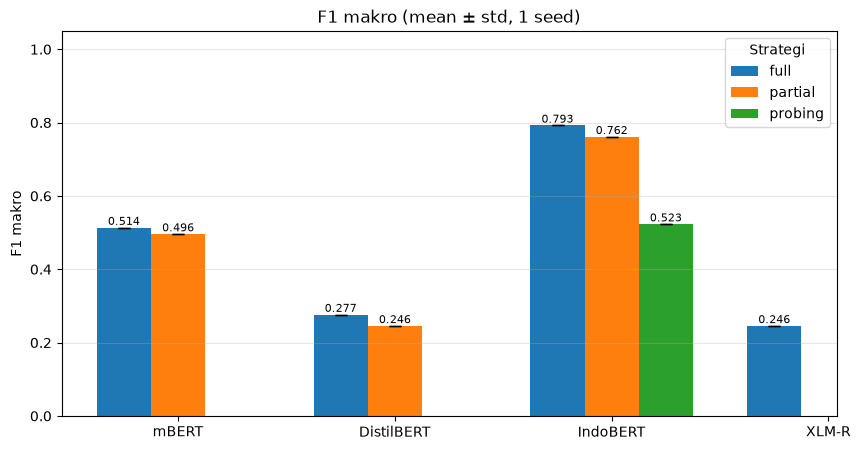

Disimpan: /home/sembiring/machine_learning/00_pr0j3ct/indo-sentiment-finetuning-benchmark/outputs/figures/f1_vs_inferensi.png


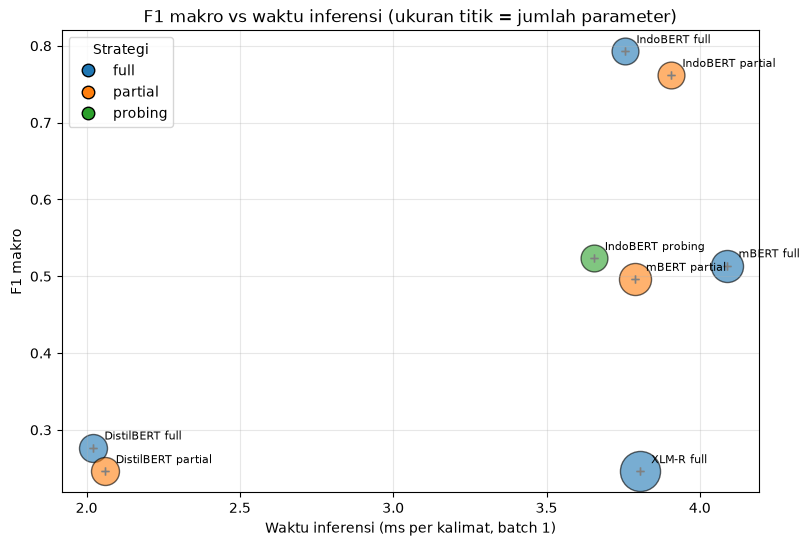

Disimpan: /home/sembiring/machine_learning/00_pr0j3ct/indo-sentiment-finetuning-benchmark/outputs/figures/waktu_latih.png


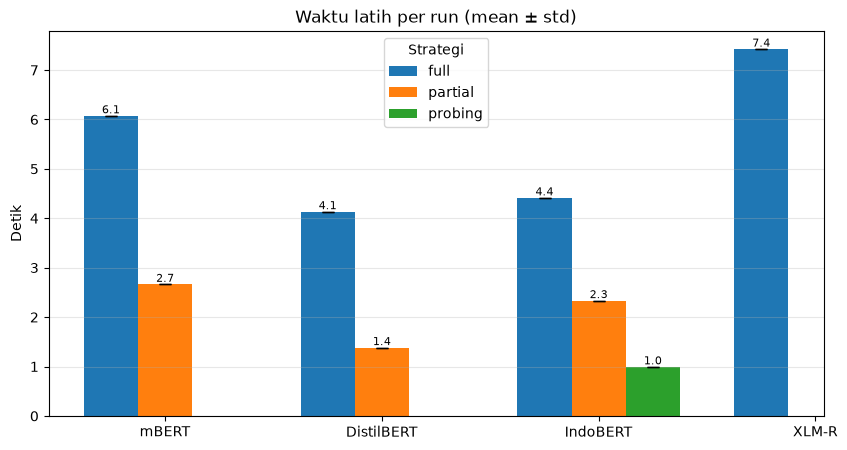

Disimpan: /home/sembiring/machine_learning/00_pr0j3ct/indo-sentiment-finetuning-benchmark/outputs/figures/confusion_matrix_terbaik.png


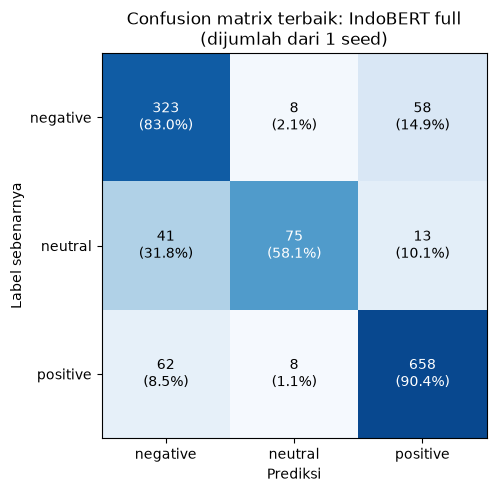


Konfigurasi terbaik: IndoBERT full | F1 makro 0.7926 ± - | F1 netral 0.6818 ± -


In [16]:
from matplotlib.lines import Line2D

WARNA_STRATEGI = {"full": "#1f77b4", "partial": "#ff7f0e", "probing": "#2ca02c"}

def ambil_nilai(rekap, backbone, strategi, kolom):
    baris = rekap[(rekap["backbone"] == backbone) & (rekap["strategy"] == strategi)]
    if len(baris) == 0:
        return None
    return baris[kolom].iloc[0]

# Daftar backbone yang ada di rekap
def backbone_yang_ada(rekap):
    backbone_di_rekap = set(rekap["backbone"])
    hasil_urut = []
    for backbone in URUTAN_BACKBONE:
        if backbone in backbone_di_rekap:
            hasil_urut.append(backbone)
    return hasil_urut

# save gambar
def simpan_dan_tampilkan(fig, nama_file):
    path_file = FIGURES_DIR / nama_file
    fig.savefig(path_file, dpi=150, bbox_inches="tight")
    print(f"Disimpan: {path_file}")
    plt.show()

def gambar_bar_kelompok(rekap, metrik, judul, label_y, nama_file, desimal_label, batas_y=None):
    daftar_backbone = backbone_yang_ada(rekap)
    posisi_x = np.arange(len(daftar_backbone))
    lebar_batang = 0.25

    fig, ax = plt.subplots(figsize=(10, 5))
    for indeks_strategi, strategi in enumerate(URUTAN_STRATEGI):
        sudah_diberi_label = False
        for indeks_backbone, backbone in enumerate(daftar_backbone):
            nilai_mean = ambil_nilai(rekap, backbone, strategi, f"{metrik}_mean")
            if nilai_mean is None:
                continue
            nilai_std = ambil_nilai(rekap, backbone, strategi, f"{metrik}_std")
            if pd.isna(nilai_std):
                nilai_std = 0.0

            x = posisi_x[indeks_backbone] + (indeks_strategi - 1) * lebar_batang
            label = strategi if not sudah_diberi_label else None
            ax.bar(x, nilai_mean, width=lebar_batang, yerr=nilai_std, capsize=4,
                   color=WARNA_STRATEGI[strategi], label=label)
            ax.text(x, nilai_mean + nilai_std, f"{nilai_mean:.{desimal_label}f}",
                    ha="center", va="bottom", fontsize=8)
            sudah_diberi_label = True

    nama_sumbu_x = []
    for backbone in daftar_backbone:
        nama_sumbu_x.append(NAMA_BACKBONE[backbone])
    ax.set_xticks(posisi_x)
    ax.set_xticklabels(nama_sumbu_x)
    ax.set_ylabel(label_y)
    ax.set_title(judul)
    if batas_y is not None:
        ax.set_ylim(batas_y)
    ax.legend(title="Strategi")
    ax.grid(axis="y", alpha=0.3)
    simpan_dan_tampilkan(fig, nama_file)


# Grafik 1: F1 makro
gambar_bar_kelompok(
    REKAP, "f1_macro",
    judul=f"F1 makro (mean ± std, {int(REKAP['n_seed'].max())} seed)",
    label_y="F1 makro", nama_file="f1_macro.png", desimal_label=3, batas_y=(0, 1.05),
)

# Grafik 2: F1 makro vs waktu inferensi
fig, ax = plt.subplots(figsize=(9, 6))
for _, baris in REKAP.iterrows():
    x = baris["infer_ms_per_sentence_mean"]
    y = baris["f1_macro_mean"]
    ukuran_titik = baris["params_total_mean"] / 1e6 * 3     # 124 jt parameter -> ukuran ~370
    ax.scatter(x, y, s=ukuran_titik, color=WARNA_STRATEGI[baris["strategy"]],
               alpha=0.6, edgecolors="black")
    std_y = 0.0 if pd.isna(baris["f1_macro_std"]) else baris["f1_macro_std"]
    std_x = 0.0 if pd.isna(baris["infer_ms_per_sentence_std"]) else baris["infer_ms_per_sentence_std"]
    ax.errorbar(x, y, xerr=std_x, yerr=std_y, fmt="none", ecolor="gray", capsize=3)
    ax.annotate(f"{NAMA_BACKBONE[baris['backbone']]} {baris['strategy']}", (x, y),
                textcoords="offset points", xytext=(8, 6), fontsize=8)

penanda_legenda = []
for strategi, warna in WARNA_STRATEGI.items():
    penanda_legenda.append(Line2D([0], [0], marker="o", color="w", markerfacecolor=warna,
                                  markeredgecolor="black", markersize=9, label=strategi))
ax.legend(handles=penanda_legenda, title="Strategi")
ax.set_xlabel("Waktu inferensi (ms per kalimat, batch 1)")
ax.set_ylabel("F1 makro")
ax.set_title("F1 makro vs waktu inferensi (ukuran titik = jumlah parameter)")
ax.grid(alpha=0.3)
simpan_dan_tampilkan(fig, "f1_vs_inferensi.png")

# Grafik 3: Waktu latih
gambar_bar_kelompok(
    REKAP, "train_time_s",
    judul="Waktu latih per run (mean ± std)",
    label_y="Detik", nama_file="waktu_latih.png", desimal_label=1,
)

# Grafik 4: Confusion matrix konfigurasi terbaik
indeks_terbaik = REKAP["f1_macro_mean"].idxmax()
backbone_terbaik = REKAP.loc[indeks_terbaik, "backbone"]
strategi_terbaik = REKAP.loc[indeks_terbaik, "strategy"]
run_terbaik = HASIL[(HASIL["backbone"] == backbone_terbaik) & (HASIL["strategy"] == strategi_terbaik)]

matriks_total = np.zeros((len(LABEL_LIST), len(LABEL_LIST)), dtype=int)
for teks_matriks in run_terbaik["confusion_matrix"]:
    matriks_total += np.array(json.loads(teks_matriks))
persen_per_baris = matriks_total / matriks_total.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(persen_per_baris, cmap="Blues", vmin=0, vmax=100)
for baris_ke in range(len(LABEL_LIST)):
    for kolom_ke in range(len(LABEL_LIST)):
        warna_teks = "white" if persen_per_baris[baris_ke, kolom_ke] > 50 else "black"
        ax.text(kolom_ke, baris_ke,
                f"{matriks_total[baris_ke, kolom_ke]}\n({persen_per_baris[baris_ke, kolom_ke]:.1f}%)",
                ha="center", va="center", color=warna_teks, fontsize=10)
ax.set_xticks(range(len(LABEL_LIST)))
ax.set_yticks(range(len(LABEL_LIST)))
ax.set_xticklabels(LABEL_LIST)
ax.set_yticklabels(LABEL_LIST)
ax.set_xlabel("Prediksi")
ax.set_ylabel("Label sebenarnya")
ax.set_title(f"Confusion matrix terbaik: {NAMA_BACKBONE[backbone_terbaik]} {strategi_terbaik}\n"
             f"(dijumlah dari {len(run_terbaik)} seed)")
simpan_dan_tampilkan(fig, "confusion_matrix_terbaik.png")

print(f"\nKonfigurasi terbaik: {NAMA_BACKBONE[backbone_terbaik]} {strategi_terbaik} | "
      f"F1 makro {REKAP.loc[indeks_terbaik, 'f1_macro_teks']} | "
      f"F1 netral {REKAP.loc[indeks_terbaik, 'f1_neutral_teks']}")

## Uji Selisih Bermakna

**Apa yang dilakukan?** Membandingkan pasangan konfigurasi yang relevan dengan hipotesis H1–H3
memakai aturan yang ditetapkan di Rancangan:

> Dua konfigurasi dianggap **berbeda meyakinkan** hanya jika |selisih rata-rata F1 makro| lebih besar
> daripada simpangan baku antar-seed (diambil yang **terbesar** dari keduanya).

**Kenapa perlu?** Selisih 0,005 bisa saja terjadi hanya karena seed yang berbeda. Kalau goyangan
antar-seed (std) lebih besar daripada selisihnya, kita belum bisa mengatakan satu konfigurasi lebih baik.
Aturan ini sederhana dan konservatif. Ini bukan uji statistik formal, dan hal itu dicatat sebagai keterbatasan.

Sel ini juga membuat **tabel efisiensi untuk H3** (mBERT vs DistilBERT): pengurangan parameter,
percepatan inferensi, dan penurunan F1.

In [17]:
# (hipotesis, konfigurasi A, konfigurasi B). Selisih = A - B.
PASANGAN_UJI = [
    ("H1", ("indobert", "full"), ("mbert", "full")),
    ("H1", ("indobert", "full"), ("distilbert", "full")),
    ("H1", ("indobert", "full"), ("xlmr", "full")),
    ("H1", ("indobert", "partial"), ("mbert", "partial")),
    ("H1", ("indobert", "partial"), ("distilbert", "partial")),
    ("H2", ("indobert", "full"), ("indobert", "partial")),
    ("H2", ("indobert", "partial"), ("indobert", "probing")),
    ("H2", ("indobert", "full"), ("indobert", "probing")),
    ("H2", ("mbert", "full"), ("mbert", "partial")),
    ("H2", ("distilbert", "full"), ("distilbert", "partial")),
    ("H3", ("mbert", "full"), ("distilbert", "full")),
    ("H3", ("mbert", "partial"), ("distilbert", "partial")),
]

# ('indobert', 'full') -> 'IndoBERT full
def nama_konfigurasi(konfigurasi):
    backbone, strategi = konfigurasi
    return f"{NAMA_BACKBONE[backbone]} {strategi}"

# membandingkan setiap pasangan
def uji_selisih_bermakna(rekap, metrik="f1_macro"):
    baris_tabel = []
    for hipotesis, konfigurasi_a, konfigurasi_b in PASANGAN_UJI:
        mean_a = ambil_nilai(rekap, konfigurasi_a[0], konfigurasi_a[1], f"{metrik}_mean")
        mean_b = ambil_nilai(rekap, konfigurasi_b[0], konfigurasi_b[1], f"{metrik}_mean")
        if mean_a is None or mean_b is None:
            continue
        std_a = ambil_nilai(rekap, konfigurasi_a[0], konfigurasi_a[1], f"{metrik}_std")
        std_b = ambil_nilai(rekap, konfigurasi_b[0], konfigurasi_b[1], f"{metrik}_std")
        selisih = mean_a - mean_b

        if pd.isna(std_a) or pd.isna(std_b):
            std_maks = float("nan")
            kesimpulan = "tidak bisa dinilai (butuh >= 2 seed)"
        else:
            std_maks = max(std_a, std_b)
            if abs(selisih) > std_maks:
                kesimpulan = "bermakna"
            else:
                kesimpulan = "belum meyakinkan"

        if selisih > 0:
            lebih_tinggi = nama_konfigurasi(konfigurasi_a)
        else:
            lebih_tinggi = nama_konfigurasi(konfigurasi_b)

        baris_tabel.append({
            "hipotesis": hipotesis,
            "A": nama_konfigurasi(konfigurasi_a),
            "B": nama_konfigurasi(konfigurasi_b),
            f"{metrik}_A": round(mean_a, 4),
            f"{metrik}_B": round(mean_b, 4),
            "selisih (A-B)": round(selisih, 4),
            "std_maks": round(std_maks, 4),
            "lebih_tinggi": lebih_tinggi,
            "kesimpulan": kesimpulan,
        })
    return pd.DataFrame(baris_tabel)

# Membandingkan mBERT vs DistilBERT: pengurangan parameter, percepatan inferensi, perubahan F1.
def tabel_efisiensi_h3(rekap):
    baris_tabel = []
    for strategi in ["full", "partial"]:
        params_mbert = ambil_nilai(rekap, "mbert", strategi, "params_total_mean")
        params_distil = ambil_nilai(rekap, "distilbert", strategi, "params_total_mean")
        if params_mbert is None or params_distil is None:
            continue
        infer_mbert = ambil_nilai(rekap, "mbert", strategi, "infer_ms_per_sentence_mean")
        infer_distil = ambil_nilai(rekap, "distilbert", strategi, "infer_ms_per_sentence_mean")
        latih_mbert = ambil_nilai(rekap, "mbert", strategi, "train_time_s_mean")
        latih_distil = ambil_nilai(rekap, "distilbert", strategi, "train_time_s_mean")
        f1_mbert = ambil_nilai(rekap, "mbert", strategi, "f1_macro_mean")
        f1_distil = ambil_nilai(rekap, "distilbert", strategi, "f1_macro_mean")

        baris_tabel.append({
            "strategi": strategi,
            "parameter_berkurang_%": round((1 - params_distil / params_mbert) * 100, 1),
            "inferensi_lebih_cepat_x": round(infer_mbert / infer_distil, 2),
            "latih_lebih_cepat_x": round(latih_mbert / latih_distil, 2),
            "f1_mbert": round(f1_mbert, 4),
            "f1_distilbert": round(f1_distil, 4),
            "f1_distil_sebagai_%_mbert": round(f1_distil / f1_mbert * 100, 1),
        })
    return pd.DataFrame(baris_tabel)


UJI_SELISIH = uji_selisih_bermakna(REKAP, metrik="f1_macro")
path_uji_selisih = OUTPUT_DIR / f"uji_selisih_smsa_{KODE}.csv"
UJI_SELISIH.to_csv(path_uji_selisih, index=False)

print("UJI SELISIH BERMAKNA (F1 makro): bermakna jika |selisih| > std maksimum antar-seed")
display(UJI_SELISIH)
print(f"Disimpan: {path_uji_selisih}")

print("\nEFISIENSI H3: mBERT vs DistilBERT")
display(tabel_efisiensi_h3(REKAP))

UJI SELISIH BERMAKNA (F1 makro): bermakna jika |selisih| > std maksimum antar-seed


,hipotesis,A,B,f1_macro_A,f1_macro_B,selisih (A-B),std_maks,lebih_tinggi,kesimpulan
0,H1,IndoBERT full,mBERT full,0.7926,0.5138,0.2788,NaN,IndoBERT full,tidak bisa dinilai (butuh >= 2 seed)
1,H1,IndoBERT full,DistilBERT full,0.7926,0.2766,0.5159,NaN,IndoBERT full,tidak bisa dinilai (butuh >= 2 seed)
2,H1,IndoBERT full,XLM-R full,0.7926,0.2459,0.5467,NaN,IndoBERT full,tidak bisa dinilai (butuh >= 2 seed)
3,H1,IndoBERT partial,mBERT partial,0.7616,0.4962,0.2654,NaN,IndoBERT partial,tidak bisa dinilai (butuh >= 2 seed)
4,H1,IndoBERT partial,DistilBERT partial,0.7616,0.2459,0.5158,NaN,IndoBERT partial,tidak bisa dinilai (butuh >= 2 seed)
5,H2,IndoBERT full,IndoBERT partial,0.7926,0.7616,0.0309,NaN,IndoBERT full,tidak bisa dinilai (butuh >= 2 seed)
6,H2,IndoBERT partial,IndoBERT probing,0.7616,0.5233,0.2384,NaN,IndoBERT partial,tidak bisa dinilai (butuh >= 2 seed)
7,H2,IndoBERT full,IndoBERT probing,0.7926,0.5233,0.2693,NaN,IndoBERT full,tidak bisa dinilai (butuh >= 2 seed)
8,H2,mBERT full,mBERT partial,0.5138,0.4962,0.0176,NaN,mBERT full,tidak bisa dinilai (butuh >= 2 seed)
9,H2,DistilBERT full,DistilBERT partial,0.2766,0.2459,0.0308,NaN,DistilBERT full,tidak bisa dinilai (butuh >= 2 seed)


Disimpan: /home/sembiring/machine_learning/00_pr0j3ct/indo-sentiment-finetuning-benchmark/outputs/uji_selisih_smsa_317c2d7c.csv

EFISIENSI H3: mBERT vs DistilBERT


,strategi,parameter_berkurang_%,inferensi_lebih_cepat_x,latih_lebih_cepat_x,f1_mbert,f1_distilbert,f1_distil_sebagai_%_mbert
0,full,23.9,2.02,1.47,0.5138,0.2766,53.8
1,partial,23.9,1.84,1.93,0.4962,0.2459,49.5


## Kesimpulan

> Diisi setelah `MODE="penuh"` selesai. Setiap klaim harus merujuk ke angka di rekap atau tabel uji selisih.

**H1 (backbone):** _diterima / ditolak / sebagian_. IndoBERT full: F1 makro ... ± ...; mBERT full: ... ± ...;
DistilBERT full: ... ± ...; XLM-R full: ... ± .... Selisih IndoBERT vs ... _bermakna / belum meyakinkan_.

**H2 (strategi):** _diterima / ditolak / sebagian_. Pada IndoBERT: full ... > partial ... > probing ....
Partial menghemat waktu latih ...x dan memori ... MB dengan penurunan F1 .... Waktu inferensi ketiga strategi
hampir sama, karena freezing tidak mengubah arsitektur saat prediksi.

**H3 (efisiensi):** _diterima / ditolak / sebagian_. DistilBERT ...% lebih sedikit parameter, inferensi ...x lebih
cepat, dengan F1 makro ...% dari mBERT.

**Kelas netral:** F1 netral konfigurasi terbaik ... (paling rendah di antara ketiga kelas / tidak).

**Strategi terbaik berbasis bukti:** ...

**Keterbatasan:** evaluasi memakai validasi resmi (label uji disembunyikan); hyperparameter sama untuk semua
backbone; aturan "selisih > std" bukan uji statistik formal; hanya 3 seed dan 1 dataset.